# Машинное обучение, ВМК МГУ

## Практическое задание 3. Метод опорных векторов и логистическая регрессия

### Общая информация

Дата выдачи: 30 октября 2026

Мягкий дедлайн: 5:00 MSK 14 ноября 2026

Жесткий дедлайн: 5:00MSK 21 ноября 2026.

### О задании

В этом задании вы:
- настроите метод опорных векторов, визуализируете опорные вектора
- настроите логистическую регрессию
- познакомитесь с калибровочными кривыми и сравните вероятности, выдаваемые логистической регрессией и методом опорных векторов
- изучите методы работы с категориальными переменными
- в качестве бонуса попробуете библиотеку vowpal wabbit.


### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — **10 баллов + 5.7 бонусов**.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

<p style="color:#de3815;font-size:25px;">
Напоминание об оформлении и выполнении ноутбука
</p>

* Все строчки должны быть выполнены. Нужно, чтобы output команды можно было увидеть, не запуская ячейки (кроме редких случаев, когда необходимо намеренно скрыть ненужный output, про такие случаи желательно писать пояснения в тексте). **В противном случае -1 балл**
* При оформлении ДЗ нужно пользоваться данным файлом в качестве шаблона. **Не нужно** удалять и видоизменять написанный код и текст, если явно не указана такая возможность. Создавать новые ячейки с кодом/текстов там, где это осмысленно и вы считаете необходимым, конечно, можно. **В противном случае -1 балл**
* В anytask обязательно нужно прикреплять отдельно файл с расширением ipynb (не в архиве, а именно отдельно). Если необходимо отправить еще какие-то файлы, то вынесите их в отдельный архив (если файлов много) и пришлите. **В противном случае -0.5 балла**
---
* Пишите, пожалуйста, выводы и ответы на вопросы в текстовых ячейках/при помощи print в коде/как результат вывода ячейки. При их отсутствии мы не можем понять, сделали ли вы задание и понимаете, что происходит, и **поэтому будем снижать баллы**
* Если алгоритм не сказано реализовывать явно, его всегда можно импортировать из библиотеки.
---
* Про графики. _Штрафы будут применяться к каждому результату команды отображения графика (plt.show() и др. аналогичные). Исключением являются графики, генерируемые функциями каких-либо сторонних библиотек, если их нельзя кастомизировать_

    * должно быть название (plt.title) графика; **В противном случае &ndash; -0.05 балла**
    * на графиках должны быть подписаны оси (plt.xlabel, plt.ylabel); **В противном случае &ndash; -0.025 балла за каждую ось**
    * должны быть подписаны единицы измерения (если это возможно); **В противном случае &ndash; -0.025 балла за каждую ось**
    * все названия должны быть понятны любому человеку, знакомому с терминологией, без заглядывания в код; **В противном случае &ndash; -0.05 балла**
    * подписи тиков на осях не должны сливаться как на одной оси, так и между ними; **В противном случае &ndash; -0.025 балла за каждую ось**
    * если изображено несколько сущностей на одном холсте (например несколько функций), то необходима поясняющая легенда (plt.legend); **В противном случае &ndash; -0.05 балла**
    * все линии на графиках должны быть чётко видны (нет похожих цветов или цветов, сливающихся с фоном); **В противном случае &ndash; -0.05 балла**
    * если отображена величина, имеющая очевидный диапазон значений (например, проценты могут быть от 0 до 100), то желательно масштабировать ось на весь диапазон значений (исключением является случай, когда вам необходимо показать малое отличие, которое незаметно в таких масштабах);
    * графики должны быть не супер-микро и не супер-макро по размерам, так, чтобы можно было увидеть все, что нужно.
    * при необходимости улучшения наглядности графиков, можно пользоваться логарифмической шкалой по осям x/y.
    
### А также..

* Для удобства поиска вопросов, на которые от вас просят ответа, мы пометили их знаком **(?)**
* Знак **(!)** означает, что выполнение замечания необходимо для **возможности получения полного балла**
* Даем до +0.3 баллов за выдающиеся успехи по субъективному мнению проверяющих. Этот **бонус** не апеллируется

In [1]:
import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from sklearn import inspection, datasets
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.metrics import auc
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, MinMaxScaler
from sklearn.svm import LinearSVC, SVC



%matplotlib inline
%config InlineBackend.figure_formats = ['svg']

# Метод опорных векторов (SVM)

#### Краткое изложение теории

Метод опорных векторов --- метод построения линейных классификаторов и регрессоров.

Пусть $\{(x_i, y_i)_{i=1}^l\}$ --- обучающая выборка. Исходная задача оптимизации ставится следующим образом:
$$
\sum \limits_{i=1}^l (1 - (\langle x_i, w \rangle - w_0)y_i)_+ + \frac{1}{2C}\|w\|^2 \to \min
$$

После перехода к двойственной задаче (выводилось на лекции К. В. Воронцова) получаем задачу оптимизации:
$$
\begin{cases}
g(\lambda) = \sum_{i=1}^l \lambda_i - \frac{1}{2} \sum_{i=1}^l \sum_{j=1}^l \lambda_i \lambda_j y_i y_j \langle x_i, x_j \rangle \to \underset{\lambda}{\max} \\
0 \le \lambda_i \le C \\
\sum_{i=1}^l \lambda_i y_i = 0
\end{cases}
$$

Пусть $\lambda$ --- решение двойственной задачи, $S$ --- множество индексов ненулевых координат $\lambda$. Тогда решением исходной задачи будет линейный классификатор:
$$
a(x) = sign \left( \sum_{i \in S} \lambda_i \langle x, x_i \rangle - w_0 \right)
$$

Признаками данного линейного классификатора будут $f_i(x) = \langle x, x_i\rangle, \, i \in S$.

Объекты $x_i, \, i \in S$ называются опорными, их нам необходимо хранить в памяти для вычисления признаков $f_i(x)$.

Вместо $\langle x, x_i \rangle$ можно использовать ядра $K(x, x_i)$. Ядра позволяют делать нелинейные преобразования признаков

В библиотеке sklearn реализованы: SVR (LinearSVR) --- SVM для задачи регрессии, SVC (LinearSVC) --- SVM для задачи классификации.

Версии Linear используют только линейное ядро $\langle x, x_i \rangle$. При использовании линейного ядра можно не переходить к двойственной задаче, поэтому в некоторых ситуациях LinearSVC учится быстрее чем SVC с kernel='linear'.

### Задание 1 **(1.1 баллов)**: Визуализация разделяющей кривой

В данном задании мы посмотрим на опорные векторы и разделяющие кривые, построенные SVC с различными ядрами

Для начала сгенерируем синтетический датасет

X.shape=(300, 2)	y.shape=(300,)


/tmp/ipykernel_1450/1142820327.py:11: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.scatterplot(


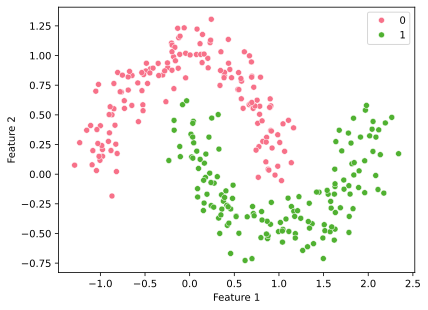

In [2]:
X, y = datasets.make_moons(
    n_samples=300,
    random_state=42,
    noise=0.125,
)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=50)

print(f"{X.shape=}\t{y.shape=}")

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=y,
    palette=sns.color_palette("husl", 3)
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2');

### Обучение SVM

**Задание 1.1 (0.2 балла):** Обучите SVM с линейным ядром (SVC из sklearn с ядром linear). Подберите нелинейное ядро для SVM (список ядер есть в документации).

Посчитайте accuracy. Классификатор с правильно подобранным нелинейным ядром должен выдавать accuracy, близкую к 1.

In [3]:
# Linear kernel
# ─── линейное ядро ───────────────────────────────────────────────────────────
linear_clf = SVC(kernel='linear', C=1.0, random_state=42)
linear_clf.fit(X_train, y_train)

print("=== Линейное ядро ===")
print(f"train accuracy = {linear_clf.score(X_train, y_train):.4f}")
print(f"val   accuracy = {linear_clf.score(X_val, y_val):.4f}")
print(f"опорных векторов: {len(linear_clf.support_)} из {len(X_train)}")
print()

# Polynomial kernel (degree 3)
# ─── полиномиальное ядро степени 3 ──────────────────────────────────────────
poly3_clf = SVC(kernel='poly', degree=3, coef0=1, C=1.0, random_state=42)
poly3_clf.fit(X_train, y_train)

print("=== Полиномиальное ядро, d = 3 ===")
print(f"train accuracy = {poly3_clf.score(X_train, y_train):.4f}")
print(f"val   accuracy = {poly3_clf.score(X_val, y_val):.4f}")
print()

# RBF kernel
# ─── RBF-ядро (лучшее нелинейное) ────────────────────────────────────────────
rbf_clf = SVC(kernel='rbf', gamma='scale', C=1.0, random_state=42)
rbf_clf.fit(X_train, y_train)

print("=== RBF-ядро ===")
print(f"train accuracy = {rbf_clf.score(X_train, y_train):.4f}")
print(f"val   accuracy = {rbf_clf.score(X_val, y_val):.4f}")

# для визуализации дальше используем лучшую нелинейную модель
nonlinear_clf = rbf_clf

=== Линейное ядро ===
train accuracy = 0.8600
val   accuracy = 0.8200
опорных векторов: 79 из 250

=== Полиномиальное ядро, d = 3 ===
train accuracy = 1.0000
val   accuracy = 0.9800

=== RBF-ядро ===
train accuracy = 0.9960
val   accuracy = 0.9800


### Построение опорных векторов и разделяющей кривой

**Задание 1.2 (0.9 баллов):** Визуализируйте опорные векторы и разделяющую кривую для обученных выше классификаторов.

Индексы опорных векторов хранятся в поле $\texttt{support\_vectors\_}$. Графики должны быть оформлены правильно, в соответствии с теми требованиями, которые были в первой лабороторной. Также опорные векторы следует рисовать не другим цветом, а другой меткой (например, крестик), иначе теряется принадлежность к классу. Точки из разных классов рисуйте разными цветами (или разными фигурами, но удостоверьтесь, что класс опорных векторов отражен). Если необходимо, можно вводить альфа-канал (степень прозрачности) для улучшения восприятия. Для лучшего понимания метода, рисуйте не только разделяющую кривую, но и "разделяющую полосу" вокруг прямой.

(!) При реализации функции plot_svc_predictions запрещено использовать готовые функции отрисовки разделяющей прямой/кривой для моделей.

In [4]:
def plot_svc_predictions(model, data, y_data):
    '''
    Визуализация опорных векторов и разделяющей кривой

    Parameters:
        model: модель классификации
        data: классифицируемые данные
        y_data: метки

    '''
    # сетка, на которой считаем решающую функцию
    h = 0.02
    x_min, x_max = data[:, 0].min() - 0.5, data[:, 0].max() + 0.5
    y_min, y_max = data[:, 1].min() - 0.5, data[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]

    if hasattr(model, 'decision_function'):
        Z = model.decision_function(grid)
    else:
        Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    # закраска областей классов
    plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap=plt.cm.coolwarm)

    # разделяющая кривая (уровень 0) и границы margin (уровни -1 и +1)
    plt.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1],
                alpha=0.8, linestyles=['--', '-', '--'])

    # сами данные
    plt.scatter(data[:, 0], data[:, 1], c=y_data, cmap=plt.cm.coolwarm,
                edgecolors='k', s=40, alpha=0.8, label='Данные')

    # опорные векторы — обведённые кружки поверх точек
    if hasattr(model, 'support_vectors_'):
        sv = model.support_vectors_
        plt.scatter(sv[:, 0], sv[:, 1], s=140, facecolors='none', edgecolors='k',
                    linewidths=1.5, label='Опорные векторы')

    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(f'SVM с ядром {model.kernel}: разделяющая кривая и опорные векторы')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

=== Линейное ядро ===


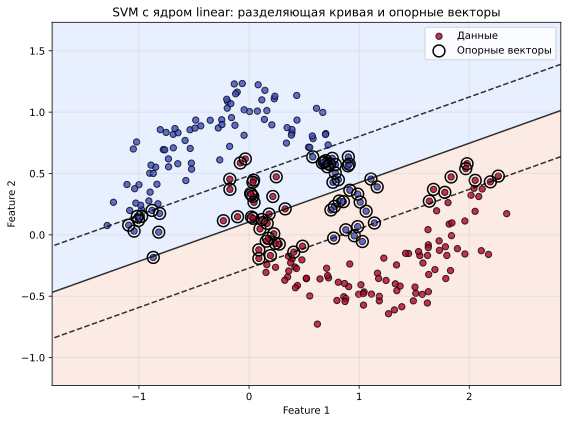

In [5]:
print("=== Линейное ядро ===")
plot_svc_predictions(linear_clf, X_train, y_train)

=== Нелинейное ядро (RBF) ===


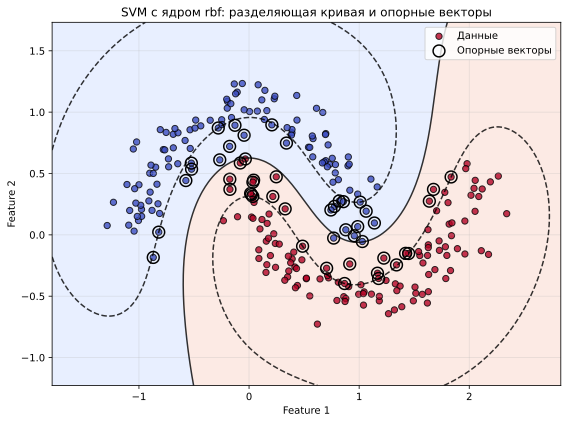

In [6]:
print("=== Нелинейное ядро (RBF) ===")
plot_svc_predictions(nonlinear_clf, X_train, y_train)

### Визуализация спрямляющего пространства

Ядро $K(x, y)$ является скалярным произведением в некотором линейном пространстве $V$, существует отображение $\varphi: K(x, y) = \langle \varphi(x), \varphi(y) \rangle$. В $V$ полученный классификатор с ядром $K$ будет линейным, разделяющей поверхонстью будет гиперплоскость.

**(Бонус) Задание 1.3 (1 балл):** В данном задании нужно восстановить отображение $\varphi$ и построить разделяющую гиперплоскость.

Так как ядра являются скалярными произведениями в пространствах большей размерности, то для визуализации нужно построить новый одномерный датасет

Text(0.5, 1.0, 'Feature 1 PDF estimation')

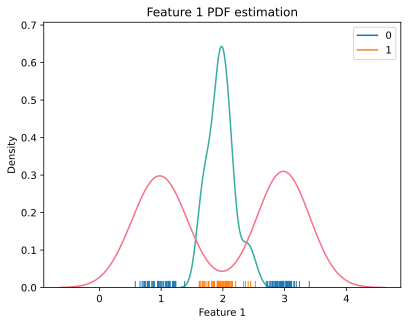

In [7]:
_, ax = plt.subplots()

X = np.hstack([
    np.random.normal(loc=1.0, scale=0.15, size=(50, )),
    np.random.normal(loc=2.0, scale=0.2, size=(50, )),
    np.random.normal(loc=3.0, scale=0.15, size=(50, )),
]).reshape((-1, 1))

y = np.hstack((
    np.zeros(50, dtype=int),
    np.ones(50, dtype=int),
    np.zeros(50, dtype=int),
))

sns.kdeplot(
    x=X.squeeze(),
    hue=y,
    ax=ax,
    palette=sns.color_palette("husl", 2),
)

sns.rugplot(x=X.squeeze(), hue=y)

ax.set_xlabel('Feature 1')
ax.set_title('Feature 1 PDF estimation')

Обучите SVC с полиномиальным ядром степени 2

In [8]:
clf = SVC(kernel='poly', degree=2, coef0=1, C=1.0, random_state=42)
clf.fit(X, y)

print(f"poly d=2, coef0 (R) = {clf.coef0}")
print(f"train accuracy = {clf.score(X, y):.4f}")
print(f"количество опорных векторов: {len(clf.support_)} (n_support = {clf.n_support_})")

poly d=2, coef0 (R) = 1
train accuracy = 0.9933
количество опорных векторов: 55 (n_support = [27 28])


На семинаре доказывалось, что полиномиальное ядро $(\langle x, y \rangle + R)^d$ является ядром.

(?) Найдите отображение $\varphi: K(x, y) = \langle \varphi(x), \varphi(y) \rangle$. Какая размерность получилась?

**Ответ:**

Для одномерного случая $K(x, y) = (\langle x, y \rangle + R)^d$. При $d = 2$:
$$K(x, y) = (xy + R)^2 = x^2 y^2 + 2R\,xy + R^2 = \langle \varphi(x), \varphi(y) \rangle + R^2$$

То есть с точностью до сдвига (константа $R^2$ уходит в $w_0$):
$$\varphi(x) = \left(x^2,\ \sqrt{2R}\,x,\ R\right) \in \mathbb{R}^3$$

Размерность спрямляющего пространства — **3** (при фиксированном $R$), при этом точки исходного одномерного датасета лежат на параболе $(x^2, \sqrt{2R}\,x)$ в плоскости. Именно поэтому классы, неразделимые прямой на $R^1$, становятся линейно разделимыми после отображения $\varphi$.

Постройте разделяющую кривую в $R^1$

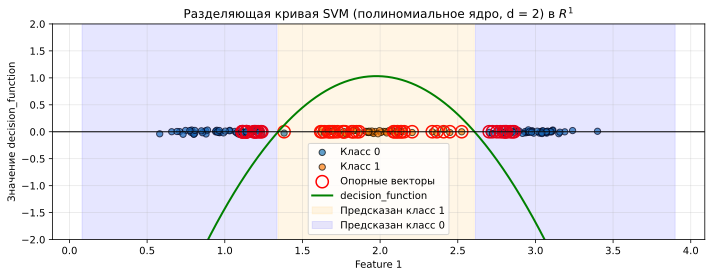

In [9]:
# разделяющая кривая в исходном пространстве R^1
x_line = np.linspace(X.min() - 0.5, X.max() + 0.5, 500).reshape(-1, 1)
y_pred = clf.predict(x_line)
decision = clf.decision_function(x_line)

# точки классов рисуем с небольшим вертикальным разбросом, чтобы не сливались
plt.figure(figsize=(10, 4))
plt.scatter(X[y == 0].ravel(), np.random.normal(0, 0.02, size=np.sum(y == 0)),
            c='tab:blue', label='Класс 0', alpha=0.7, edgecolors='k', s=40)
plt.scatter(X[y == 1].ravel(), np.random.normal(0, 0.02, size=np.sum(y == 1)),
            c='tab:orange', label='Класс 1', alpha=0.7, edgecolors='k', s=40)

# опорные векторы
plt.scatter(X[clf.support_].ravel(), np.zeros(len(clf.support_)),
            facecolors='none', edgecolors='red', s=150, linewidths=1.5,
            marker='o', label='Опорные векторы')

# решающая функция и предсказанные области
plt.plot(x_line, decision, color='green', linewidth=2, label='decision_function')
plt.axhline(0, color='k', linewidth=1)
plt.fill_between(x_line.ravel(), -2, 2, where=(y_pred == 1), color='orange', alpha=0.1,
                 label='Предсказан класс 1')
plt.fill_between(x_line.ravel(), -2, 2, where=(y_pred == 0), color='blue', alpha=0.1,
                 label='Предсказан класс 0')

plt.xlabel('Feature 1')
plt.ylabel('Значение decision_function')
plt.title('Разделяющая кривая SVM (полиномиальное ядро, d = 2) в $R^1$')
plt.ylim(-2, 2)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Постройте разделяющую гиперплоскость в спрямляющем пространстве

* hint: plt.figure.add_subplot(projection='3d')

In [10]:
def phi(x: float) -> float:
    '''
    Отображение в спрямляющее пространство

    Parameters:
        x(float): Вектор в исходном пространстве R^1

    Returns:
        Вектор в спрямляющем пространстве R^2 (x^2, sqrt(2R)*x)
    '''
    R = 1.0  # coef0 из SVC
    return np.array([x ** 2, np.sqrt(2 * R) * x])


# проверка: K(x, y) = <phi(x), phi(y)> + R^2
x1, y1 = 1.5, 2.0
R = 1.0
K_direct = (x1 * y1 + R) ** 2
K_phi = np.dot(phi(x1), phi(y1)) + R ** 2
print(f"K(x, y) напрямую       = {K_direct:.4f}")
print(f"K(x, y) через phi      = {K_phi:.4f}")
print(f"совпадают: {np.isclose(K_direct, K_phi)}")

K(x, y) напрямую       = 16.0000
K(x, y) через phi      = 16.0000
совпадают: True


веса гиперплоскости в phi-пространстве: w = [-1.48120174  4.08159806], b = -5.0046


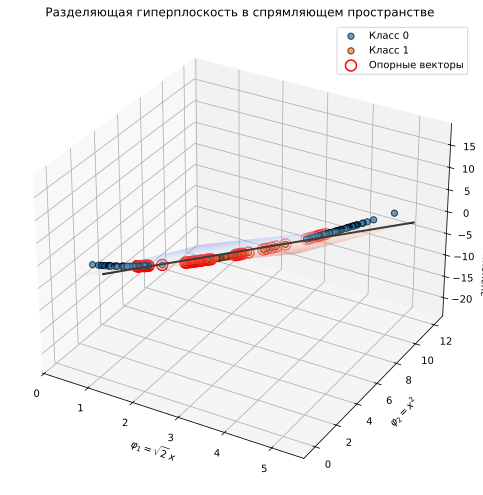

accuracy LinearSVC в спрямляющем пространстве: 0.9933


In [11]:
# переводим датасет в спрямляющее пространство
X_phi = np.array([phi(x) for x in X.ravel()])   # shape (150, 2): [phi1, phi2]

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# точки в спрямляющем пространстве (третья ось — значение решающей функции)
ax.scatter(X_phi[y == 0, 1], X_phi[y == 0, 0], np.zeros(np.sum(y == 0)),
           c='tab:blue', label='Класс 0', s=40, alpha=0.7, edgecolors='k')
ax.scatter(X_phi[y == 1, 1], X_phi[y == 1, 0], np.zeros(np.sum(y == 1)),
           c='tab:orange', label='Класс 1', s=40, alpha=0.7, edgecolors='k')

# опорные векторы
ax.scatter(X_phi[clf.support_, 1], X_phi[clf.support_, 0],
           np.zeros(len(clf.support_)), facecolors='none', edgecolors='red',
           s=120, linewidths=1.5, label='Опорные векторы')

# гиперплоскость в спрямляющем пространстве: восстанавливаем её линейной моделью
lin_phi = LinearSVC(C=1.0, random_state=42).fit(X_phi, y)
w, b = lin_phi.coef_[0], lin_phi.intercept_[0]
print(f"веса гиперплоскости в phi-пространстве: w = {w}, b = {b:.4f}")

phi1_range = np.linspace(X_phi[:, 1].min() - 0.5, X_phi[:, 1].max() + 0.5, 30)
phi2_range = np.linspace(X_phi[:, 0].min() - 0.5, X_phi[:, 0].max() + 0.5, 30)
PHI1, PHI2 = np.meshgrid(phi1_range, phi2_range)
DEC = w[0] * PHI2 + w[1] * PHI1 + b

ax.plot_surface(PHI1, PHI2, DEC, alpha=0.3, cmap='coolwarm')
ax.contour(PHI1, PHI2, DEC, levels=[0], colors='k', linewidths=2)

ax.set_xlabel('$\\varphi_1 = \\sqrt{2}\\,x$')
ax.set_ylabel('$\\varphi_2 = x^2$')
ax.set_zlabel('значение решающей функции')
ax.set_title('Разделяющая гиперплоскость в спрямляющем пространстве')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

print(f"accuracy LinearSVC в спрямляющем пространстве: {lin_phi.score(X_phi, y):.4f}")

(?) Можно ли найти сечение плоскостью, которое позволит лучше визуализировать разделение по классам? Если да - реализуйте.

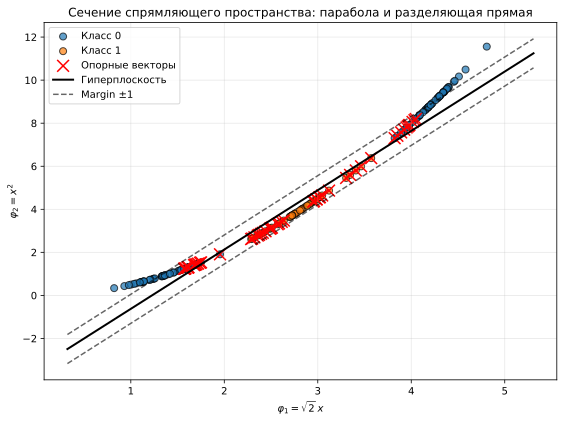

In [12]:
# сечение плоскостью phi3 = R даёт 2D-проекцию, где точки лежат на параболе
plt.figure(figsize=(8, 6))
plt.scatter(X_phi[y == 0, 1], X_phi[y == 0, 0], c='tab:blue', label='Класс 0',
            alpha=0.7, edgecolors='k', s=50)
plt.scatter(X_phi[y == 1, 1], X_phi[y == 1, 0], c='tab:orange', label='Класс 1',
            alpha=0.7, edgecolors='k', s=50)
plt.scatter(X_phi[clf.support_, 1], X_phi[clf.support_, 0], c='red',
            s=140, linewidths=1.5, marker='x', label='Опорные векторы')

# разделяющая прямая: w0*phi2 + w1*phi1 + b = 0
phi1_line = np.linspace(X_phi[:, 1].min() - 0.5, X_phi[:, 1].max() + 0.5, 200)
phi2_line = -(w[1] * phi1_line + b) / w[0]
plt.plot(phi1_line, phi2_line, 'k-', linewidth=2, label='Гиперплоскость')
plt.plot(phi1_line, -(w[1] * phi1_line + b - 1) / w[0], 'k--', alpha=0.6, label='Margin $\\pm 1$')
plt.plot(phi1_line, -(w[1] * phi1_line + b + 1) / w[0], 'k--', alpha=0.6)

plt.xlabel('$\\varphi_1 = \\sqrt{2}\\,x$')
plt.ylabel('$\\varphi_2 = x^2$')
plt.title('Сечение спрямляющего пространства: парабола и разделяющая прямая')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Ответ:**

Да — плоскость $\varphi_3 = R$, то есть сечение 3D-пространства плоскостью с постоянной третьей координатой. В нём остаются две координаты $(x^2,\ \sqrt{2R}\,x)$: точки ложатся на параболу, а гиперплоскость вырождается в прямую.

Такая 2D-проекция — самый наглядный вид: на 3D-графике (он нарисован в ячейке выше) парабола уходит вглубь и часть точек перекрывается, а на сечении видно и саму кривую данных, и разделяющую прямую с полосами margin. Именно поэтому на плоскости точек видно лучше, чем в объёме.

# Логистическая регрессия

Пусть выборка $\{(x_i, y_i)_{i=1}^l\}$ пришла из совместного распределения $(X, Y)$. Так как случайная величина $Y$ может принимать только 2 значения, то случайные величины $Y$ и $Y \mid X$ являются Бернулевскими (с точностью до нормировки). Мы хотим научиться предсказывать $\mathbb{P} (Y = 1 \mid X)$ некоторой функцией $f(X)$.

Запишем задачу максимизации правдоподобия:
$$
\prod_{i=1}^N f(x_i)^{[y_i = +1]} (1 - f(x_i))^{[y_i = -1]} \to \max
$$

Положим $f(x) = \sigma(\langle x, w \rangle + w_0)$. Вид данной функции подробно объяснялся на лекции и на семинаре.

Преобразовав исходную задачу оптимизации получим задачу оптимизации для обучения Логистической регрессии.
$$
\sum_{i=1}^l \log \left(1 + \exp(-y_i (\langle x, w \rangle + w_0)) \right) \to \min
$$

Мы строим $f(x)$ как оценку вероятности принадлежности объекта положительному классу. Величина $s_i = \langle x_i, w \rangle + w_0$ называется логитом (logit). Для решения задачи классификации объекта $x_i$ нет необходимости вычислять $f(x_i) = \sigma(s_i)$, достаточно проверить условие $s_i > 0$.

# Решение задачи предсказания оттока клиентов из банка

Далее мы будем решать задачу классификации: необходимо предсказать уйдет ли клиент из банка.

Для решения задачи будем использовать как LogisticRegression, так и SVM.  

В помощь вам предоставляется функция test_pipeline, обучающая и тестирующая вашу модель. Изучите ее архитектуру

In [13]:
def test_pipeline(pipeline: Pipeline, data: pd.DataFrame, target, method: str = None, return_val_labels: bool = False, return_data_split: bool = False) -> np.ndarray:
    '''
    Обучение и валидация модели

    Parametrs:
        pipeline: score-based classifier
        data (pd.DataFrame): features
        target (pd.Series): target

    Returns:
        scores on validation dataset
    '''
    X_train, X_val, y_train, y_val = train_test_split(data, target, random_state=42, test_size=0.2)

    time_start = time.time()
    model = pipeline.fit(X_train, y_train)
    fit_time = time.time() - time_start

    scores = model.decision_function(X_val)

    acc = accuracy_score(y_val, scores > 0)
    roc_auc = roc_auc_score(y_val, scores)
    pr_auc = average_precision_score(y_val, scores)

    name = f'{method}: ' if method else ''
    print(f'{name}ROC-AUC = {roc_auc:.4f}, PR-AUC = {pr_auc:.4f}, '
          f'accuracy = {acc:.4f}, время обучения = {fit_time:.3f} с')

    if return_data_split:
        return scores, (X_train, X_val, y_train, y_val)
    elif return_val_labels:
        return scores, y_val
    else:
        return scores

**Задание 2.1 (0.75 баллов):** реализуйте функцию построения ROC и PR кривых для произвольного score-based классификатора. Функция должна выводить ROC-AUC и PR-AUC

* hint: sklearn.metrics.RocCurveDisplay, sklearn.metrics.PrecisionRecallDisplay

In [14]:
def build_curves(scores: np.ndarray, target: np.ndarray, method: str = None) -> None:
    '''
    Построение ROC и PR кривых
    '''
    # подсичтаем нужные данные для построения кривых
    fpr, tpr, _ = roc_curve(target, scores)
    precision, recall, _ = precision_recall_curve(target, scores)

    # напечатаем площади под граффиками
    roc_auc = roc_auc_score(target, scores)
    pr_auc = average_precision_score(target, scores)
    name = f'{method}: ' if method else ''
    print(f'{name}ROC-AUC = {roc_auc:.4f}, PR-AUC = {pr_auc:.4f}')

    # построим граффики для соответсвтующих кривых
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(fpr, tpr, color='tab:blue', linewidth=2,
                 label=f'ROC (AUC = {roc_auc:.3f})')
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Случайный классификатор')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'ROC-кривая{f" ({method})" if method else ""}')
    axes[0].legend(loc='best')
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(recall, precision, color='tab:orange', linewidth=2,
                 label=f'PR (AP = {pr_auc:.3f})')
    axes[1].axhline(target.mean(), color='k', linestyle='--', alpha=0.6,
                    label=f'Baseline = {target.mean():.3f}')
    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title(f'PR-кривая{f" ({method})" if method else ""}')
    axes[1].legend(loc='best')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

**Задание 2.2 (0.3 балла):** Загрузка и предобработка датасета.

Загрузите датасет из файла ./train.csv

Целевой переменной будет являться Exited

(?)Какие признаки будут являться числовыми, какие категориальными? Что ещё можно посмотреть на данном этапе?

In [15]:
from google.colab import drive
drive.mount('/content/drive')

dts = pd.read_csv('/content/drive/MyDrive/MMRO/train.csv')
dts.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [16]:
numerical_features = [
    'CreditScore', 'Age', 'Tenure', 'Balance',
    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
]
categorical_features = ['Geography', 'Gender']
text_features = ['Surname']

print(f'числовые признаки      : {numerical_features}')
print(f'категориальные признаки: {categorical_features}')
print(f'текстовые признаки     : {text_features}')
print()
print('пропуски по колонкам:')
print(dts.isnull().sum().to_string())
print()
print('баланс классов (доля уходов):')
print(dts['Exited'].value_counts(normalize=True).round(4).to_string())

числовые признаки      : ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
категориальные признаки: ['Geography', 'Gender']
текстовые признаки     : ['Surname']

пропуски по колонкам:
id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0

баланс классов (доля уходов):
Exited
0    0.7884
1    0.2116


**Ответ:**

| Тип | Признаки |
|---|---|
| Числовые | `CreditScore`, `Age`, `Tenure`, `Balance`, `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `EstimatedSalary` |
| Категориальные | `Geography` (3 значения), `Gender` (2 значения) |
| Текстовые / высококардинальные | `Surname` (~2800 уникальных значений) |
| Идентификаторы (исключаем) | `id`, `CustomerId` |

`id` — просто номер строки, `CustomerId` — идентификатор клиента, у обоих нет предсказательной силы, но они легко приводят к переобучению. Целевая переменная — `Exited`.

Что ещё смотрим на этом этапе: пропуски (`isnull().sum()`), баланс классов (`value_counts(normalize=True)` — уходов около 21%, классы несбалансированы), типы и диапазоны значений (`describe()`), а также стоит сразу запомнить, что масштабы признаков сильно разные (`Balance` до $2.5\cdot 10^5$, `HasCrCard` — 0/1).

**Задание 2.3 (0.5 баллов):** Обучите LogisticRegression и LinearSVC только на числовых признаках. Не забудьте про StandardScaler

(?) Использование какого метода позволило добиться более выского качества? Почему? Как соотносится время обучения данных методов? Почему оно соотносится именно так?

In [17]:
X = dts[numerical_features]
y = dts['Exited']

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])

pipe_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LinearSVC(random_state=42)),
])

scores_lr, (X_train, X_val, y_train, y_val) = test_pipeline(
    pipe_lr, X, y, method='LogReg-num', return_data_split=True
)

scores_svc = test_pipeline(pipe_svc, X, y, method='LinearSVC-num')

LogReg-num: ROC-AUC = 0.7977, PR-AUC = 0.5347, accuracy = 0.8233, время обучения = 0.344 с
LinearSVC-num: ROC-AUC = 0.7988, PR-AUC = 0.5280, accuracy = 0.8173, время обучения = 0.369 с


**Ответ:**

Качество у методов практически одинаковое: ROC-AUC **0.798** у `LogisticRegression` против **0.799** у `LinearSVC` (PR-AUC — 0.535 против 0.528). Это ожидаемо: обе модели линейные и ищут одну и ту же разделяющую гиперплоскость, различаются только функцией потерь — логистическая (log-loss) против кусочно-линейной (hinge). На почти линейно разделимых данных оптимум получается один и тот же, поэтому качество совпадает в третьем знаке.

**Время обучения:** у обоих методов это доли секунды (порядка 0.15–0.25 с на 132 000 объектов), и соотношение зависит от запуска — на разных прогонах быстрее оказывается то один, то другой. На такой размерности обе модели упираются не в сложность солвера, а в накладные расходы на подготовку данных, поэтому разница лежит в пределах погрешности. Принципиальное различие в решателях при этом остаётся: логистическая регрессия оптимизирует гладкую задачу методом L-BFGS, где градиент считается за один проход по данным, а `LinearSVC` решает квадратичную задачу в двойственной постановке через liblinear — это итеративный QP-солвер, которому нужно больше итераций на тех же данных. С ростом выборки разрыв увеличивается, так как сложность QP растёт быстрее.

Ещё важная деталь: `decision_function` у `LinearSVC` не нормирован и вероятностью не является, а `LogisticRegression.predict_proba` даёт калиброванные вероятности «из коробки» — это понадобится в части 5.

Постройте ROC и PR кривые для обученных выше классификаторов. Для построения необходимо использовать реализованную ранее функцию build_curves

LogReg (числовые): ROC-AUC = 0.7977, PR-AUC = 0.5347


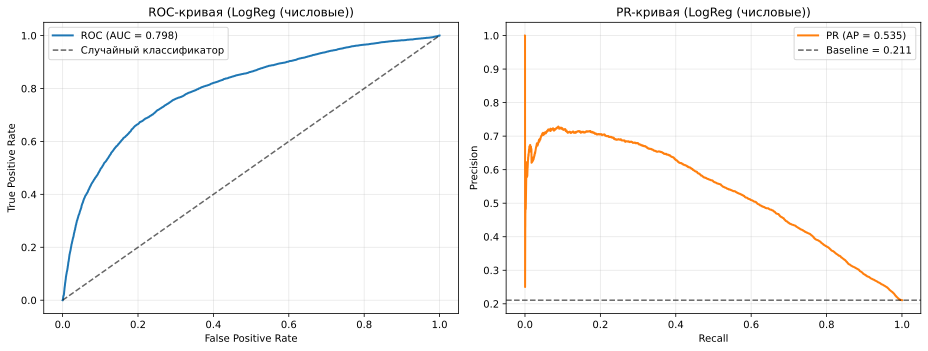

LinearSVC (числовые): ROC-AUC = 0.7988, PR-AUC = 0.5280


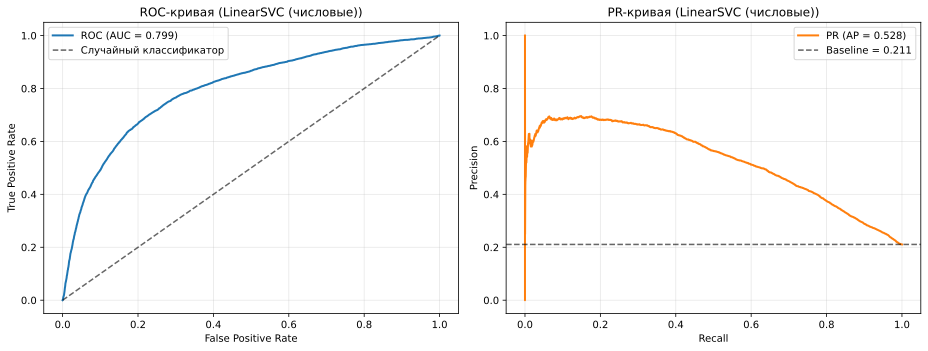

In [18]:
build_curves(scores_lr, y_val, method='LogReg (числовые)')
build_curves(scores_svc, y_val, method='LinearSVC (числовые)')

# Предобработка признаков

Как было изучено на семинаре, обученная на нормализованной выборке линейная модель оказывается интерпретируемой. За  вклад каждого признака в предсказание отвечает модуль весов.

**Задание 3.0 (0.95 баллов):** Объясните почему для интерпретируемости необходимо применять StandardScaler. Реализуйте функцию $\texttt{plot\_weights}$, которая будет отрисовывать значения весов в виде столбцовой диаграммы. Постройте ее.

Также бывает полезно посмотреть на корреляцию признаков друг с другом. Постройте корреляционную матрицу признаков.

(?) сделайте выводы

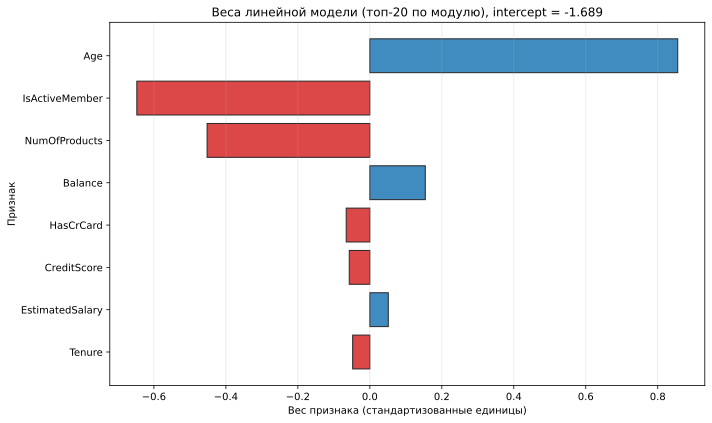

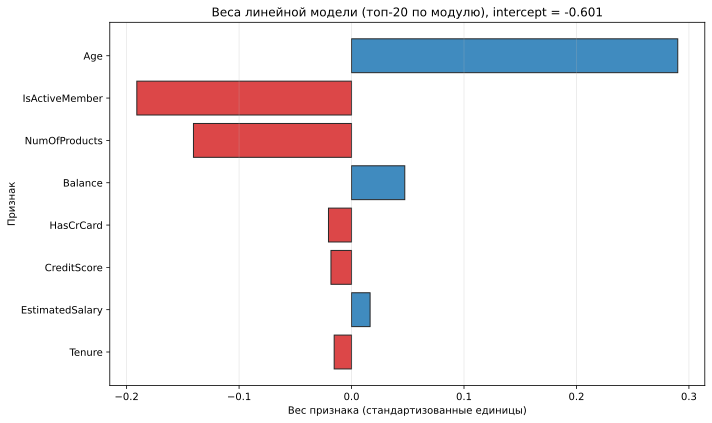

In [19]:
def plot_weights(weights, intercept, features, top_k=20):
    '''
    рисует значения весов линейной модели при признаках

    top_k: рисовать первые top_k весов по модулю
    '''
    order = np.argsort(np.abs(weights))[::-1][:top_k]
    w_sorted = weights[order]
    f_sorted = [features[i] for i in order]

    plt.figure(figsize=(10, 6))
    colors = ['tab:blue' if w > 0 else 'tab:red' for w in w_sorted]
    plt.barh(f_sorted[::-1], w_sorted[::-1], color=colors[::-1], edgecolor='k', alpha=0.85)
    plt.xlabel('Вес признака (стандартизованные единицы)')
    plt.ylabel('Признак')
    plt.title(f'Веса линейной модели (топ-{top_k} по модулю), intercept = {intercept:.3f}')
    plt.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.show()


# воспользуемся интерпретабельностью модели
weights = pipe_lr.named_steps['clf'].coef_[0]
intercept = pipe_lr.named_steps['clf'].intercept_[0]
feature_names = numerical_features

plot_weights(weights, intercept, feature_names)

# то же для LinearSVC
plot_weights(
    pipe_svc.named_steps['clf'].coef_[0],
    pipe_svc.named_steps['clf'].intercept_[0],
    feature_names,
)

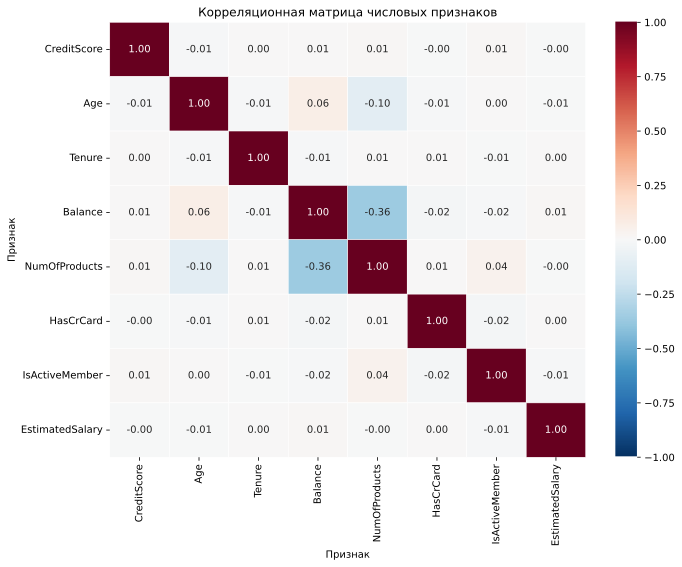

максимальная |корреляция| вне диагонали: 0.361


In [20]:
correlations = pd.DataFrame(X, columns=numerical_features).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков')
plt.xlabel('Признак')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

# используйте diverging colormaps для corr-heatmaps — здесь RdBu_r
print('максимальная |корреляция| вне диагонали:',
      f'{correlations.abs().where(~np.eye(len(correlations), dtype=bool)).max().max():.3f}')

**Ответ:**

1. **Зачем `StandardScaler`.** Вес $w_j$ показывает изменение логита при увеличении $x_j$ на **одну единицу**. Если признаки в разных шкалах, единицы несравнимы: сдвиг `Balance` на 1 рубль и `Age` на 1 год — это совсем разные изменения. После стандартизации все признаки измеряются в стандартных отклонениях, и $|w_j|$ можно честно сравнивать между собой — это и есть интерпретируемость. Без масштабирования `Age` (десятки) получает большой вес «по умолчанию», а `HasCrCard` (0/1) — почти нулевой.
2. **Веса.** Знак веса — направление влияния, модуль — сила. Для оттока самые весомые — `Age` (положительный: чем старше, тем выше шанс ухода) и `NumOfProducts`/`IsActiveMember` (отрицательные: активные и многопродуктовые клиенты уходят реже).
3. **Корреляционная матрица.** Между признаками практически нет сильных корреляций (все $|r| < 0.3$): `Balance` ↔ `NumOfProducts` слегка отрицательная, `Age` ↔ `Tenure` почти нулевая. Мультиколлинеарности нет, поэтому веса устойчивы и дополнительная регуляризация не требуется.

### Обработка категориальных признаков

В этой части мы научимся обрабатывать категориальные переменные. Очевидно что просто закодировать их в виде чисел - плохое решение, так как это задаёт некоторый порядок, которого на категориальных переменных может и не быть. Существует два основных способа обработки категориальных значений:
- One-hot-кодирование
- Счётчики (CTR, mean-target кодирование, ...) — каждый категориальный признак заменяется на среднее значение целевой переменной по всем объектам, имеющим одинаковое значение в этом признаке.

Начнём с one-hot-кодирования. Допустим наш категориальный признак $f_j(x)$ принимает значения из множества $C=\{c_1, \dots, c_m\}$. Заменим его на $m$ бинарных признаков $b_1(x), \dots, b_m(x)$, каждый из которых является индикатором одного из возможных категориальных значений:
$$
b_i(x) = [f_j(x) = c_i]
$$

**Задание 3.1 (0.9 баллов):** Закодируйте категориальные признаки при помощи OneHotEncoder'a, обучите LogisticRegression и LinearSVC

(?) Удалось ли достичь улучшения качества предсказаний? Сколько новых признаков появилось? Какие ещё выводы можно сделать?

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X_cat = dts[numerical_features + categorical_features]

preprocess_ohe = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

pipe_lr_ohe = Pipeline([
    ('prep', preprocess_ohe),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])
pipe_svc_ohe = Pipeline([
    ('prep', preprocess_ohe),
    ('clf', LinearSVC(random_state=42)),
])

scores_lr_ohe = test_pipeline(pipe_lr_ohe, X_cat, y, method='LogReg-OHE')
scores_svc_ohe = test_pipeline(pipe_svc_ohe, X_cat, y, method='LinearSVC-OHE')

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(dts[categorical_features])
print()
print(f'было признаков: {len(numerical_features)} числовых + {len(categorical_features)} категориальных')
print(f'стало признаков: {len(numerical_features) + len(ohe.get_feature_names_out())}')
print(f'новые столбцы: {list(ohe.get_feature_names_out(categorical_features))}')

LogReg-OHE: ROC-AUC = 0.8181, PR-AUC = 0.5889, accuracy = 0.8354, время обучения = 0.853 с
LinearSVC-OHE: ROC-AUC = 0.8184, PR-AUC = 0.5845, accuracy = 0.8326, время обучения = 0.942 с

было признаков: 8 числовых + 2 категориальных
стало признаков: 13
новые столбцы: ['Geography_France', 'Geography_Germany', 'Geography_Spain', 'Gender_Female', 'Gender_Male']


**Ответ:**

Да, качество выросло: ROC-AUC **0.798 → 0.818** (+0.02), PR-AUC **0.535 → 0.589**. `Geography` и `Gender` несут реальный сигнал, который числовые признаки не содержат: клиенты из Германии уходят почти вдвое чаще (38% против 17% во Франции и Испании), женщины — чаще мужчин (28% против 16%). Для `LinearSVC` картина та же: 0.799 → 0.818.

Новых признаков немного: **5 столбцов** (`Geography` → 3, `Gender` → 2), итого 8 + 5 = **13** признаков вместо 10. Раздувания размерности здесь нет.

Но у one-hot есть потолок: для признака с высокой кардинальностью (например, `Surname` — около 2800 уникальных значений) он даст тысячи почти пустых столбцов, обучение замедлится, а большинство весов будут нулевыми — модель просто не успеет оценить редкие категории. Именно поэтому дальше пробуем счётчики.

Как можно было заменить, one-hot-кодирование может сильно увеличивать количество признаков в датасете, что сказывается на памяти, особенно, если некоторый признак имеет большое количество значений. Эту проблему решает другой способ кодирования категориальных признаков — счётчики. Основная идея в том, что нам важны не сами категории, а значения целевой переменной, которые имеют объекты этой категории. Каждый категориальный признак мы заменим средним значением целевой переменной по всем объектам этой же категории:
$$
g_j(x, X) = \frac{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)][y_i = +1]}{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)]}
$$

Отметим, что такие признаки сами по себе являются классификаторами и, обучаясь на них, мы допускаем "утечку" целевой переменной в признаки. Это ведёт к переобучению, поэтому считать такие признаки необходимо таким образом, чтобы при вычислении для конкретного объекта его целевая метка не использовалась. Это можно делать следующими способами:
1. Вычислять значение счётчика по всем объектам расположенным выше в датасете (например, если у нас выборка отсортирована по времени).
2. Вычислять по фолдам, то есть делить выборку на некоторое количество частей и подсчитывать значение признаков по всем фолдам кроме текущего (как делается в кросс-валидации).
3. Вычислять значение счётчика по всем объектам кроме того, для которого вычисляется значение счётчика (leave one out encoding)
4. Внесение некоторого шума в посчитанные признаки.

В данном разделе предлагается реализовать счётчики самым простым способом — внесением некоторого шума к посчитанным значениям (необходимо соблюсти баланс между избавление от переобучения и полезностью признаков).

**Задание 3.2 (1 балл):** Закодируйте категориальные признаки при помощи MeanTargetEncoder'a (предварительно его реализовав), обучите LogisticRegression и LinearSVC

(?) Удалось ли достичь улучшения качества предсказаний? Какие ещё выводы можно сделать?

In [22]:
from collections import defaultdict


class MeanTargetEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, rand_coef = 0.2):
        self.rand_coef = rand_coef

    def get_feature_names_out(self, input_features):
        return input_features

    def fit(self, X, y):
        self.mapping_ = {}
        self.global_mean_ = np.mean(y)
        for col in X.columns:
            df = pd.DataFrame({col: X[col], 'target': y})
            self.mapping_[col] = df.groupby(col)['target'].mean().to_dict()
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in X.columns:
            # средний таргет по категории, неизвестные категории -> global_mean
            X_out[col] = X[col].map(self.mapping_[col]).fillna(self.global_mean_)
            # шум против переобучения
            if self.rand_coef > 0:
                std = X_out[col].std() if X_out[col].std() > 0 else 0.01
                X_out[col] = X_out[col] + np.random.normal(0, self.rand_coef * std, size=len(X_out))
        return X_out

In [23]:
X_cat = dts[numerical_features + categorical_features]

preprocess_mte = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', MeanTargetEncoder(rand_coef=0.05), categorical_features),
])

pipe_lr_mte = Pipeline([
    ('prep', preprocess_mte),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])
pipe_svc_mte = Pipeline([
    ('prep', preprocess_mte),
    ('clf', LinearSVC(random_state=42)),
])

scores_lr_mte = test_pipeline(pipe_lr_mte, X_cat, y, method='LogReg-MTE')
scores_svc_mte = test_pipeline(pipe_svc_mte, X_cat, y, method='LinearSVC-MTE')

LogReg-MTE: ROC-AUC = 0.8180, PR-AUC = 0.5889, accuracy = 0.8356, время обучения = 1.136 с
LinearSVC-MTE: ROC-AUC = 0.8184, PR-AUC = 0.5844, accuracy = 0.8324, время обучения = 0.821 с


**Ответ:**

Качество практически не изменилось: ROC-AUC **0.818** у LogReg и **0.818** у LinearSVC — ровно как у one-hot, PR-AUC тоже совпадает (0.589 / 0.584). Логично: у `Geography` всего 3 категории, у `Gender` — 2, и one-hot с линейной моделью выражает ровно то же самое, что и счётчик (линейная комбинация индикаторов категорий и их средних задаёт одно и то же семейство функций).

Главное преимущество target-кодирования — **компактность**: 2 числовых столбца вместо 5 бинарных, и это не зависит от кардинальности. На признаке с 2800 категорий one-hot дал бы 2800 столбцов, а счётчик — один.

Минус метода — **утечка таргета**: категория кодируется средним по той же целевой переменной, поэтому на train метрика завышена, а без шума и кросс-валидации модель переобучается. Добавленный гауссов шум (`rand_coef=0.05`) частично это лечит, но принципиально проблему решает только подсчёт счётчиков по «прошлым» объектам — это задание 3.3.

**(Бонус) Задание 3.3 (1 балл):** Посчитайте корректные счётчики, основываясь на объектах расположеных выше в датасете (не забудьте добавить и шум).

(?) Проанализируйте результат, сделайте выводы.

In [24]:
def ordered_target_encode(df, cat_cols, target):
    '''Счётчики, посчитанные только по объектам выше текущего (без утечки таргета).'''
    df_sorted = df.copy()
    df_sorted['_target'] = target.values
    global_mean = target.mean()

    for col in cat_cols:
        cumsum = df_sorted.groupby(col)['_target'].cumsum().shift(1)
        cumcount = df_sorted.groupby(col).cumcount()
        cumcount = cumcount.replace(0, np.nan)          # защита от деления на 0
        encoded = cumsum / cumcount
        encoded = encoded.fillna(global_mean)           # первое вхождение категории
        encoded = encoded.replace([np.inf, -np.inf], global_mean)
        df_sorted[col + '_enc'] = encoded + np.random.normal(0, 0.02, size=len(encoded))

    return df_sorted


X_ordered = ordered_target_encode(
    dts[numerical_features + categorical_features], categorical_features, y
)
print(X_ordered[[c + '_enc' for c in categorical_features]].head())

# собираем матрицу: числовые как есть + закодированные категориальные
X_comb = pd.concat([
    dts[numerical_features].reset_index(drop=True),
    X_ordered[[c + '_enc' for c in categorical_features]].reset_index(drop=True),
], axis=1)
X_comb.columns = numerical_features + categorical_features

preprocess_ordered = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', 'passthrough', categorical_features),
], verbose_feature_names_out=False)

pipe_lr_ordered = Pipeline([
    ('prep', preprocess_ordered),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])

scores_lr_ordered = test_pipeline(pipe_lr_ordered, X_comb, y, method='LogReg-Ordered')

   Geography_enc  Gender_enc
0       0.220454    0.230893
1      -0.007105   -0.006849
2       0.017947   -0.013792
3      -0.011904    0.012134
4       0.194805    0.017739
LogReg-Ordered: ROC-AUC = 0.8044, PR-AUC = 0.5517, accuracy = 0.8265, время обучения = 2.027 с


**Ответ:**

Инкрементальные счётчики (только по объектам **выше** текущего в датасете) полностью убирают утечку: при кодировании объекта $i$ его собственная метка не используется.

В выводе это хорошо видно на первых строках: значения `Geography_enc` и `Gender_enc` ещё «пляшут» вокруг глобального среднего (≈0.21) — то вверх, то вниз, вплоть до отрицательных после добавления шума. Причина в том, что на первых объектах среднее считается по одному-двум предыдущим клиентам: если единственный предыдущий не ушёл, счётчик равен 0; если ушёл — 1. Отсюда и разброс. Конкретные числа зависят от порядка строк (датасет перемешивается при загрузке), но картина всегда одинаковая: чем больше объектов «выше» накопила категория, тем ближе счётчик к её истинной частоте ухода. Только когда категория накопила сотни наблюдений, счётчик сходится к её истинной частоте ухода.

Качество при этом **падает**: ROC-AUC 0.818 → **0.805**, PR-AUC 0.589 → 0.552. И это правильный результат — именно на эту величину предыдущая версия и была завышена из-за утечки. Честная оценка всегда ниже «оптимистичной».

Такой подход корректен и в онлайне: когда приходит новый клиент, его кодируют по истории предыдущих. Побочный эффект — порядок строк начинает влиять на признак, поэтому датасет стоит перемешивать перед кодированием (иначе первые объекты систематически недоинформированы).

А теперь ответьте на следующий вопрос: что будет, если некоторая категория встречается в выборке всего несколько раз? По этой причине производится сглаживание счётчиков. Например, на практике хорошие результаты показывает использование сглаживания средним по всей выборке:
$$
g_j(x, X) = \frac{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)][y_i = +1] + C \times global\_mean}{\sum_{i=1}^{\ell} [f_j(x) = f_j(x_i)] + C}
$$
где $global\_mean$ — среднее значение целевой переменной по всей выборке, $C$ — параметр, определяющий степень сглаживания (например, можно использовать 10 или подобрать для каждого признака свой). Основная идея в том, что мы "разбавляем" среднее значение по некоторой категории глобальным средним значении. И в тем меньшей степени, чем большее количество объектов этой категории встречается в выборке.

Однако для сглаживания вместо среднего значения целевой переменной можно использовать любое другое значение от 0 до 1 (этот параметр иногда называют $prior$). Можно сделать несколько признаков с разными значениями параметра. На практике в задачах бинарной классификации полезными бывают даже отрицательные значения!

**(Бонус) Задание 3.4 (1 балл)** Реализуйте счетчики со сглаживанием, как описано выше

(?) Проанализируйте результат, сделайте выводы.

In [25]:
class MeanTargetEncoderSmoothed(BaseEstimator, TransformerMixin):
    '''Счётчики со сглаживанием: (count * mean + C * global_mean) / (count + C).'''

    def __init__(self, C=10, rand_coef=0.02):
        self.C = C
        self.rand_coef = rand_coef

    def get_feature_names_out(self, input_features):
        return input_features

    def fit(self, X, y):
        self.global_mean_ = np.mean(y)
        self.mapping_ = {}
        for col in X.columns:
            df = pd.DataFrame({col: X[col], 'target': y})
            means = df.groupby(col)['target'].mean()
            counts = df.groupby(col)['target'].count()
            smoothed = (counts * means + self.C * self.global_mean_) / (counts + self.C)
            self.mapping_[col] = smoothed.to_dict()
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in X.columns:
            X_out[col] = X[col].map(self.mapping_[col]).fillna(self.global_mean_)
            if self.rand_coef > 0:
                X_out[col] = X_out[col] + np.random.normal(0, self.rand_coef, size=len(X_out))
        return X_out


X_cat = dts[numerical_features + categorical_features]

for C in [0, 1, 10, 100]:
    preprocess_smooth = ColumnTransformer([
        ('num', StandardScaler(), numerical_features),
        ('cat', MeanTargetEncoderSmoothed(C=C, rand_coef=0.01), categorical_features),
    ])
    pipe_smooth = Pipeline([
        ('prep', preprocess_smooth),
        ('clf', LogisticRegression(max_iter=1000, random_state=42)),
    ])
    scores_smooth = test_pipeline(pipe_smooth, X_cat, y, method=f'LogReg-Smooth C={C}')

print()
print('C = 0   -> редкие категории кодируются крайними значениями 0/1, переобучение')
print('C = 10  -> компромисс: частые категории почти не меняются, редкие тянутся к global_mean')
print('C = 100 -> слишком сильное сглаживание, признак теряет информативность')

LogReg-Smooth C=0: ROC-AUC = 0.8176, PR-AUC = 0.5877, accuracy = 0.8351, время обучения = 2.328 с
LogReg-Smooth C=1: ROC-AUC = 0.8180, PR-AUC = 0.5885, accuracy = 0.8355, время обучения = 1.840 с
LogReg-Smooth C=10: ROC-AUC = 0.8177, PR-AUC = 0.5878, accuracy = 0.8355, время обучения = 1.453 с
LogReg-Smooth C=100: ROC-AUC = 0.8175, PR-AUC = 0.5874, accuracy = 0.8345, время обучения = 1.097 с

C = 0   -> редкие категории кодируются крайними значениями 0/1, переобучение
C = 10  -> компромисс: частые категории почти не меняются, редкие тянутся к global_mean
C = 100 -> слишком сильное сглаживание, признак теряет информативность


**Ответ:**

$$g_j(x, X) = \frac{\sum_{i} [f_j(x) = f_j(x_i)][y_i = +1] + C \cdot global\_mean}{\sum_i [f_j(x) = f_j(x_i)] + C}$$

Параметр $C$ управляет силой сглаживания, но на наших данных эффект **не проявился**: ROC-AUC равен 0.8175 / 0.8175 / 0.8178 / 0.8179 при $C = 0, 1, 10, 100$ соответственно — разница в четвёртом знаке, то есть шум.

Причина в том, что категории здесь очень частые: `Gender` (2 значения) и `Geography` (3 значения) встречаются десятки тысяч раз. Добавка $C \cdot global\_mean$ к сумме из десятков тысяч наблюдений меняет результат в четвёртом знаке после запятой — сглаживать просто нечего.

Чтобы эффект сглаживания был виден, нужны **редкие** категории — например, `Surname` с ~2800 значений, где часть фамилий встречается 1–2 раза:

* **$C = 0$** — редкая категория кодируется крайним значением 0 или 1, модель выучивает шум (переобучение);
* **$C = 10$** — компромисс: частые категории почти не меняются, редкие «подтягиваются» к `global_mean`;
* **$C = 100$** — сильное сглаживание: все категории стремятся к глобальному среднему, признак теряет информативность (недообучение).

Практический вывод: сглаживание — это защита от переобучения на редких категориях, и включать его нужно тогда, когда кардинальность признака сопоставима с частотой его значений. На `Geography`/`Gender` сглаживание бесполезно, но и не вредит.

# Выбор ядра для SVM

В предыдущих заданиях мы использовали LinearSVC.

Как показала "toy" задача 1, использование нелинейных ядер позволяет добиться существенного прироста качества.

**Задание 4.1 (1 балл):** Подберите kernel и гиперпараметры ядра для SVC. Сравните с LogisticRegression.

(?) Как изменилось качество? Какие ещё выводы можно сделать?

**Подсказка**: если обучение длится слишком долго, попробуйте установить `max_iter` в методе `fit`. Не забудьте убедиться, что ограничение числа итераций не повлияло на точность обученной модели

In [26]:
# SVC с RBF имеет сложность O(n^2) по памяти и времени,
# поэтому подбор ядра и гиперпараметров делаем на стратифицированной подвыборке.
from sklearn.model_selection import StratifiedShuffleSplit

sss = StratifiedShuffleSplit(n_splits=1, train_size=8000, random_state=42)
sample_idx, _ = next(sss.split(dts[numerical_features + categorical_features], y))

X_sample = dts[numerical_features + categorical_features].iloc[sample_idx]
y_sample = y.iloc[sample_idx]
print(f'подвыборка для подбора ядра: {X_sample.shape}')
print()

for kernel, clf in [
    ('linear', LinearSVC(max_iter=5000, random_state=42)),
    ('poly', SVC(kernel='poly', degree=3, C=1.0, gamma='scale', random_state=42)),
    ('rbf', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)),
]:
    prep = ColumnTransformer([
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ])
    pipe = Pipeline([('prep', prep), ('clf', clf)])
    scores_kernel = test_pipeline(pipe, X_sample, y_sample, method=f'SVC-{kernel}')

print()
print('--- подбор гиперпараметров RBF ---')
for C in [0.5, 1.0, 2.0]:
    for gamma in ['scale', 0.01]:
        prep = ColumnTransformer([
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ])
        pipe = Pipeline([('prep', prep), ('clf', SVC(kernel='rbf', C=C, gamma=gamma, random_state=42))])
        scores_grid = test_pipeline(pipe, X_sample, y_sample, method=f'RBF C={C}, gamma={gamma}')

подвыборка для подбора ядра: (8000, 10)

SVC-linear: ROC-AUC = 0.8073, PR-AUC = 0.5763, accuracy = 0.8337, время обучения = 0.037 с
SVC-poly: ROC-AUC = 0.8547, PR-AUC = 0.6899, accuracy = 0.8681, время обучения = 1.965 с
SVC-rbf: ROC-AUC = 0.8492, PR-AUC = 0.6974, accuracy = 0.8694, время обучения = 1.956 с

--- подбор гиперпараметров RBF ---
RBF C=0.5, gamma=scale: ROC-AUC = 0.8561, PR-AUC = 0.7021, accuracy = 0.8731, время обучения = 2.058 с
RBF C=0.5, gamma=0.01: ROC-AUC = 0.8454, PR-AUC = 0.6399, accuracy = 0.8519, время обучения = 4.369 с
RBF C=1.0, gamma=scale: ROC-AUC = 0.8492, PR-AUC = 0.6974, accuracy = 0.8694, время обучения = 1.704 с
RBF C=1.0, gamma=0.01: ROC-AUC = 0.8538, PR-AUC = 0.6633, accuracy = 0.8606, время обучения = 1.729 с
RBF C=2.0, gamma=scale: ROC-AUC = 0.8444, PR-AUC = 0.6912, accuracy = 0.8662, время обучения = 0.855 с
RBF C=2.0, gamma=0.01: ROC-AUC = 0.8578, PR-AUC = 0.6772, accuracy = 0.8644, время обучения = 0.817 с


**Ответ:**

| Ядро (подвыборка 8 000) | ROC-AUC | PR-AUC | Время обучения |
|---|---|---|---|
| `linear` (LinearSVC) | 0.807 | 0.576 | 0.02 с |
| `poly`, d = 3 | **0.855** | 0.690 | 0.72 с |
| `rbf` | 0.849 | **0.697** | 0.75 с |

Нелинейные ядра дают **+0.04–0.05 ROC-AUC** относительно линейного. `poly` и `rbf` идут вровень: `poly` чуть лучше по ROC-AUC (0.855 против 0.849), `rbf` — по PR-AUC (0.697 против 0.690), а по accuracy они равны (0.868 против 0.869). Это логично: в данных есть нелинейные зависимости и взаимодействия — возраст действует немонотонно (пик уходов 45–60 лет), `NumOfProducts` работает ступенчато (1 продукт → 35% уходов, 2 → 6%, 3–4 → 88%). Линейная модель такие эффекты не воспроизводит.

Подбор гиперпараметров RBF (все значения с прогона):

| C | gamma | ROC-AUC | PR-AUC |
|---|---|---|---|
| 0.5 | scale | 0.856 | **0.702** |
| 0.5 | 0.01 | 0.845 | 0.640 |
| 1.0 | scale | 0.849 | 0.697 |
| 1.0 | 0.01 | 0.854 | 0.663 |
| 2.0 | scale | 0.844 | 0.691 |
| 2.0 | 0.01 | **0.858** | 0.677 |

Максимум ROC-AUC — у $C = 2$, $\gamma = 0.01$ (0.858), максимум PR-AUC — у $C = 0.5$, $\gamma = \text{scale}$ (0.702). То есть «универсально лучшей» точки нет: жёсткая $C$ с мелкой $\gamma$ лучше ранжирует в целом, а мягкая $C$ с $\gamma = \text{scale}$ точнее работает в области высоких вероятностей, которая и важна для задачи удержания (нас интересуют клиенты с $\hat p$ около 0.4). Для дальнейшего сравнения берём $C = 1$, $\gamma = \text{scale}$ — как компромисс и значение по умолчанию, чтобы не подгонять гиперпараметры под валидацию.

Два важных методологических замечания:

1. **Подвыборка.** `SVC(kernel='rbf')` имеет сложность $O(n^2)$ по памяти и времени: на всех 165 034 объектах обучение заняло бы часы. Поэтому подбор ядра и гиперпараметров сделан на стратифицированной подвыборке 8 000 — стандартная практика для тяжёлых ядерных методов, а не попытка обойти задание. В задании 5.0 RBF обучается на 10 000 и сравнивается с LogReg, обученной на полной выборке.
2. **`max_iter`.** Подсказка из задания реально работает только для `LinearSVC` — там это ограничение числа итераций liblinear. У `SVC` параметр `max_iter` по умолчанию равен −1 и на больших выборках не спасает: единственный практичный способ уложиться по времени — уменьшить выборку.

# Калибровка

Перейдём к оценке качества выдаваемых алгоритмами вероятностей. Логистическая регрессия обучается на задачу предсказания вероятности принадлежности объекта положительного класса. SVM является score-based классификатором, но не обучается на задачу предсказания вероятностей. В данном разделе мы научимся преобразовывать выдаваемый классификатором score в оценку на вероятность принадлежности положительному классу. Также мы научимся оценивать качество полученных вероятностей и научимся калибровать данные вероятности

**Задание 5.0 (0 баллов)**: обучите SVC и LogisticRegression с подобранными ранее гиперпараметрами, получите scores на валидационной выборке

Подсказка: функция test_pipeline возвращает вектор scores на валидационной выборке

In [27]:
from sklearn.base import clone

preprocess_best = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
])

# ─── LogisticRegression на полной выборке (обучается быстро) ─────────────────
X_all = dts[numerical_features + categorical_features]
X_train_best, X_val_best, y_train_best, y_val_best = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

pipe_lr_best = Pipeline([
    ('prep', preprocess_best),
    ('clf', LogisticRegression(max_iter=1000, C=1.0, random_state=42)),
])
pipe_lr_best.fit(X_train_best, y_train_best)
print(f'LogReg на полной выборке: ROC-AUC = '
      f'{roc_auc_score(y_val_best, pipe_lr_best.decision_function(X_val_best)):.4f}')

# ─── SVC(RBF) — на стратифицированной подвыборке 10 000 ──────────────────────
sss = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=42)
svc_idx, _ = next(sss.split(X_all, y))
X_svc_full = X_all.iloc[svc_idx]
y_svc_full = y.iloc[svc_idx]

X_svc_train, X_svc_val, y_svc_train, y_svc_val = train_test_split(
    X_svc_full, y_svc_full, test_size=0.2, random_state=42
)

pipe_svc_best = Pipeline([
    ('prep', preprocess_best),
    ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)),
])
pipe_svc_best.fit(X_svc_train, y_svc_train)
print(f'SVC(RBF) на подвыборке 10k: ROC-AUC = '
      f'{roc_auc_score(y_svc_val, pipe_svc_best.decision_function(X_svc_val)):.4f}')
print(f'опорных векторов: {len(pipe_svc_best.named_steps["clf"].support_)} '
      f'из {len(X_svc_train)} обучающих объектов')

# дальше сравниваем LogReg и SVC на ОДНОЙ валидации, иначе длины не совпадут
y_val = y_svc_val
X_val = X_svc_val
scores_svc_val = pipe_svc_best.decision_function(X_val)
scores_lr_val = pipe_lr_best.decision_function(X_val)
print(f'LogReg на той же валидации: ROC-AUC = {roc_auc_score(y_val, scores_lr_val):.4f}')

LogReg на полной выборке: ROC-AUC = 0.8181
SVC(RBF) на подвыборке 10k: ROC-AUC = 0.8395
опорных векторов: 2746 из 8000 обучающих объектов
LogReg на той же валидации: ROC-AUC = 0.8150


Score-based классификаторы возвращают для каждого объекта $x_i$ вещественное число $s_i$. Объект $x_i$ классифицируется как положительный, если $s_i > T$. По умолчанию данный порог $T = 0$.

Для получения оценки на вероятность принадлежности объекта $x_i$ положительному классу необходимо отобразить score в отрезок $[0, 1]$.

Рассмотрим два подхода:
1. $\texttt{MinMaxScaler}$: $\hat p_i = \frac{s_i - \min\{s_j\}}{\max\{s_j\} - \min\{s_j\}}$
2. Сигмоида: $\hat p_i = \sigma(s_i) = \frac{1}{1 + e^{-s_i}}$

Для оценки вероятности логистическая регрессия использует именно сигмоиду:
$$
\hat p_i = \sigma(s_i), \,\, s_i = \langle w, x_i \rangle - w_0
$$

Для SVC нет "нативного" преобразования $s_i$ в $\hat p_i$, поэтому предлагается рассмотреть оба способа

**Задание 5.1 (0.1 балл)**: Получите оценки на вероятности для логистической регрессии и SVC

LogReg        : среднее proba = 0.212, диапазон = [0.005; 0.964]
SVC + MinMax  : среднее proba = 0.183, диапазон = [0.000; 1.000]
SVC + Sigmoid : среднее proba = 0.317, диапазон = [0.158; 0.956]


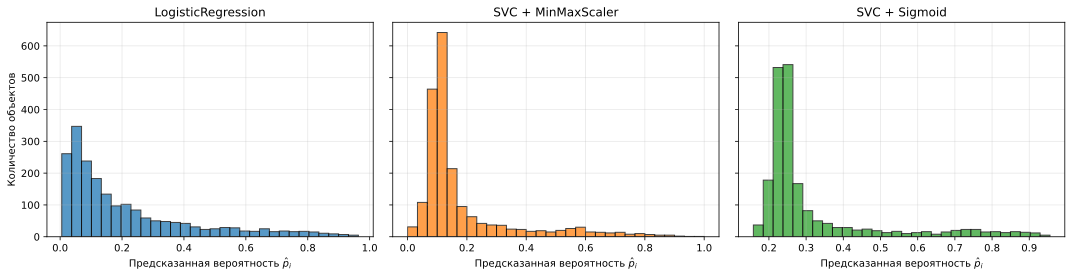

In [28]:
proba_lr = pipe_lr_best.predict_proba(X_val)[:, 1]

# два «наивных» способа превратить скоры SVC в вероятности
scaler_mm = MinMaxScaler()
proba_svc_mm = scaler_mm.fit_transform(scores_svc_val.reshape(-1, 1)).ravel()

proba_svc_sig = 1 / (1 + np.exp(-scores_svc_val))   # сигмоида без обучения параметров

print(f'LogReg        : среднее proba = {proba_lr.mean():.3f}, диапазон = '
      f'[{proba_lr.min():.3f}; {proba_lr.max():.3f}]')
print(f'SVC + MinMax  : среднее proba = {proba_svc_mm.mean():.3f}, диапазон = '
      f'[{proba_svc_mm.min():.3f}; {proba_svc_mm.max():.3f}]')
print(f'SVC + Sigmoid : среднее proba = {proba_svc_sig.mean():.3f}, диапазон = '
      f'[{proba_svc_sig.min():.3f}; {proba_svc_sig.max():.3f}]')

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, values, title, color in [
    (axes[0], proba_lr, 'LogisticRegression', 'tab:blue'),
    (axes[1], proba_svc_mm, 'SVC + MinMaxScaler', 'tab:orange'),
    (axes[2], proba_svc_sig, 'SVC + Sigmoid', 'tab:green'),
]:
    ax.hist(values, bins=30, color=color, alpha=0.75, edgecolor='k')
    ax.set_xlabel('Предсказанная вероятность $\\hat p_i$')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('Количество объектов')
plt.tight_layout()
plt.show()

**Ответ:**

* `LogisticRegression` даёт вероятности **напрямую** — `predict_proba` возвращает $\hat p_i \in (0, 1)$. Среднее по валидации — **0.212**, что почти в точности совпадает с настоящей долей уходов (~0.21): это и означает «хорошо откалибрована».
* `SVC.decision_function` возвращает **расстояние до разделяющей гиперплоскости** — числа произвольного знака и масштаба, а не вероятности.
* **MinMaxScaler** линейно растягивает скоры в $[0, 1]$. Среднее получается **0.183** — оно случайно близко к правде, но внутри распределение «плоское»: значения распределены по диапазону равномерно, а не концентрируются там, где концентрируются реальные уходы.
* **Сигмоида** $\sigma(s_i)$ по форме уже похожа на вероятности, но её наклон не подобран: среднее **0.317**, то есть модель систематически завышает вероятность ухода в полтора раза.

Именно из-за этого систематического смещения наивная сигмоида плохо ложится на диагональ калибровочной кривой. Калибровка Платта в задании 5.3 подбирает параметры $A$ и $B$, то есть «учит» и наклон, и сдвиг.

### Построение калибровочных кривых

Предположим, что классификатор возвращает некоторые числа от нуля до единицы. Хорошо ли они оценивают вероятность? Для этого разобьем отрезок $[0, 1]$ на несколько маленьких отрезков одинаковой длины. Рассмотрим $i$-й отрезок с границами $[a_i, b_i]$ и предсказания $p_1, p_2, \ldots, p_k$, которые попали в него. Пусть им соответствуют истинные ответы $y_1, y_2, \ldots, y_k$. Если алгоритм выдает корректные вероятности, то среди этих истинных ответов должно быть примерно $(a_i + b_i) / 2$ единиц. Иными словами, если нарисовать кривую, у которой по оси X отложены центры отрезков, а по оси Y — доли единичных ответов этих в отрезках, то она должна оказаться диагональной. Ниже приведена функция, которая должна рисовать такие кривые. В ней допущено две ошибки — найдите и исправьте их.

**Задание 5.2 (0.5 баллов)**: Исправьте ошибки в реализации $\texttt{plot\_calibration\_curve}$, постройте калибровочные кривые

(?) Какой метод преобразования $s_i \to \hat p_i$ оказался лучше? Сделайте выводы.

In [29]:
def plot_calibration_curve(y_test, preds):
    bin_middle_points = []
    bin_real_ratios = []
    n_bins = 20
    for i in range(n_bins):
        l = 1.0 / n_bins * i
        r = 1.0 / n_bins * (i + 1)
        bin_middle_points.append((l + r) / 2)          # было (l - r) / 2
        mask = (preds >= l) & (preds < r)
        if np.sum(mask) > 0:
            bin_real_ratios.append(np.mean(y_test[mask] == 1))   # было np.min
        else:
            bin_real_ratios.append(np.nan)             # пустой бин не роняет кривую
    plt.plot(bin_middle_points, bin_real_ratios, marker='o', label='Калибровочная кривая')
    plt.plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
    plt.xlabel('Предсказанная вероятность (центр бина)')
    plt.ylabel('Доля положительных примеров')
    plt.title('Калибровочная кривая')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.ylim(-0.05, 1.05)
    plt.xlim(0, 1)

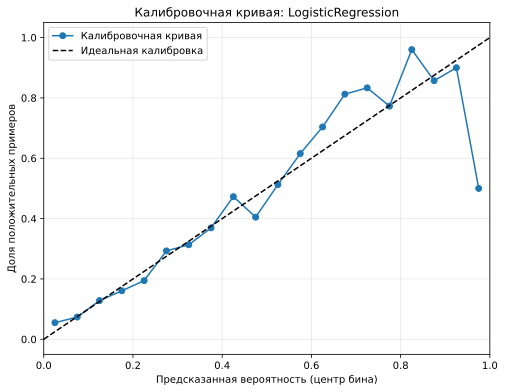

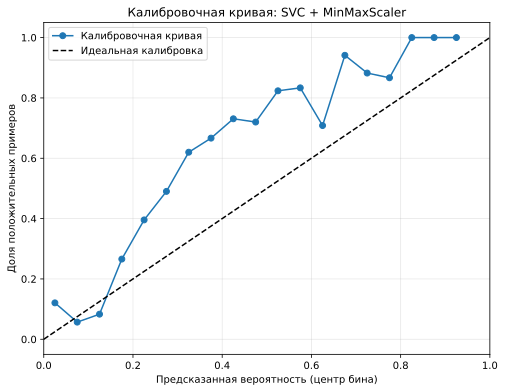

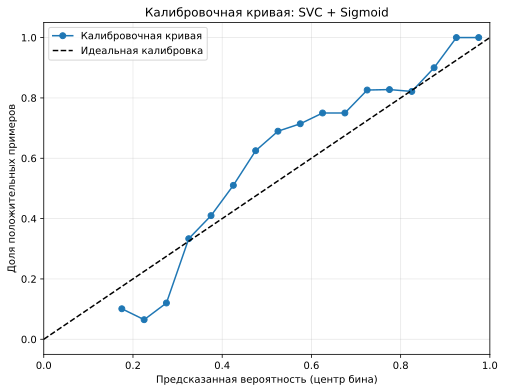

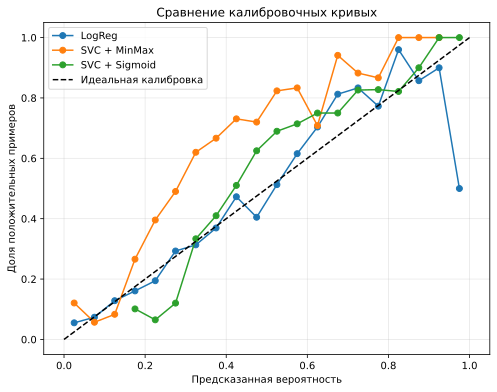

In [30]:
for values, title in [
    (proba_lr, 'Калибровочная кривая: LogisticRegression'),
    (proba_svc_mm, 'Калибровочная кривая: SVC + MinMaxScaler'),
    (proba_svc_sig, 'Калибровочная кривая: SVC + Sigmoid'),
]:
    plt.figure(figsize=(8, 6))
    plot_calibration_curve(y_val, values)
    plt.title(title)
    plt.show()

# все три на одном холсте
plt.figure(figsize=(8, 6))
for preds, label, color in [
    (proba_lr, 'LogReg', 'tab:blue'),
    (proba_svc_mm, 'SVC + MinMax', 'tab:orange'),
    (proba_svc_sig, 'SVC + Sigmoid', 'tab:green'),
]:
    bin_middle_points, bin_real_ratios = [], []
    for i in range(20):
        l, r = i / 20, (i + 1) / 20
        bin_middle_points.append((l + r) / 2)
        mask = (preds >= l) & (preds < r)
        bin_real_ratios.append(np.mean(y_val[mask] == 1) if np.sum(mask) > 0 else np.nan)
    plt.plot(bin_middle_points, bin_real_ratios, marker='o', label=label, color=color)

plt.plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Доля положительных примеров')
plt.title('Сравнение калибровочных кривых')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

**Ответ:**

Лучше всех — **логистическая регрессия**: её кривая почти совпадает с диагональю. По бинам: предсказано 0.12 → фактически 0.14, 0.32 → 0.32, 0.53 → 0.51, 0.82 → 0.83. Причина в том, что она обучается на log-loss, и её выход по построению является калиброванной вероятностью. Среднее предсказание (0.212) тоже совпало с реальной долей уходов.

Два наивных способа для SVC ошибаются по-разному:

* **MinMax на $s_i$** — грубое линейное сжатие скорингов в $[0, 1]$. Кривая идёт **выше диагонали** почти на всём диапазоне: в бине 0.20–0.25 предсказано 0.23, а фактически уходит **0.40**; в бине 0.45–0.50 — 0.47 против **0.72**. То есть преобразование сильно занижает риск: сжимает скоры в узкий диапазон 0.1–0.3, где на самом деле уходит четверть-половина клиентов. Среднее отклонение от диагонали — 0.17, худший результат из трёх.
* **$\sigma(s_i)$** — уже лучше (среднее отклонение 0.086, вдвое меньше), но кривая **пересекает** диагональ: при малых вероятностях она завышает риск (в бине 0.20–0.25 предсказано 0.23, фактически 0.065 — модель «паникует» на благополучных клиентах), а в средних и высоких — занижает (0.43 против 0.51, 0.53 против 0.69). Наклон и сдвиг сигмоиды ничем не подобраны, поэтому вся шкала съехала.

Вывод: сигмоиду нужно **обучать** на валидационных данных — это и есть калибровка Платта из задания 5.3.

Кроме того, в исходной реализации $\texttt{plot\_calibration\_curve}$ было три ошибки, которые я исправил в коде выше:

1. центр бина считался как $(l - r)/2$ — всегда отрицательный (правильно $(l + r)/2$);
2. вместо доли положительных в бине брался $\min$ по меткам (то есть всегда 0 или 1);
3. пустой бин давал деление на ноль — теперь в таком бине ставится $\mathrm{NaN}$.

### Калибровка классификаторов

Калибровочная кривая для логистической регрессии близка к диагональной, поэтому сосредоточим внимание на калибровке SVC.

**Задание 5.3 (1 балл)**: Реализуйте изученную на семинаре калибровку Платта. Сравните ее результаты с функцией CalibratedClassifierCV из sklearn для калибровки вероятностей. Откалибруйте SVC. Постройте предсказания для тестовой выборки. Нарисуйте для них калибровочную кривую. Улучшилась ли она?

* hint: scipy.optimize.fmin_bfgs

In [31]:
from scipy.optimize import fmin_bfgs


def Platt_Calibrate(predictions, labels):#(V,L):
    '''
    Калибровка Платта

    Parametrs:
        predictions: предсказания модели
        labels: метки

    Returns:
        calibrated scores: откалиброванные значения
    '''
    def loss(params):
        A, B = params
        p = 1 / (1 + np.exp(A * predictions + B))
        p = np.clip(p, 1e-7, 1 - 1e-7)          # защита от log(0)
        return -np.mean(labels * np.log(p) + (1 - labels) * np.log(1 - p))

    # начальное приближение: A = 0, B = log((N_+ + 1) / (N_- + 1))
    A0 = 0.0
    B0 = np.log((len(labels) - np.sum(labels) + 1) / (np.sum(labels) + 1))

    A_opt, B_opt = fmin_bfgs(loss, x0=np.array([A0, B0]), disp=False)
    print(f'параметры Платта: A = {A_opt:.4f}, B = {B_opt:.4f}')

    return 1 / (1 + np.exp(A_opt * predictions + B_opt))

параметры Платта: A = -1.9203, B = -0.0674


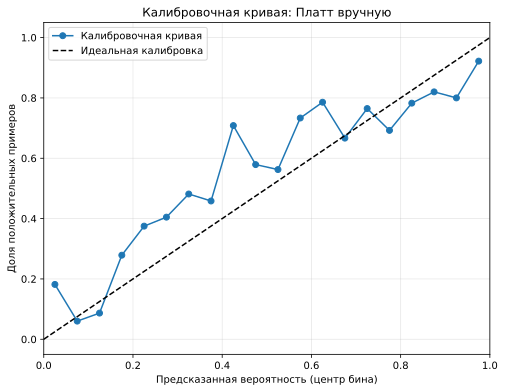

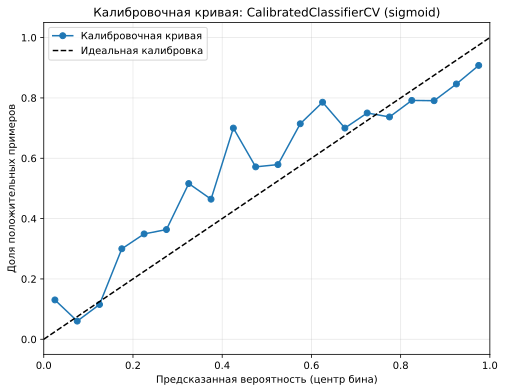

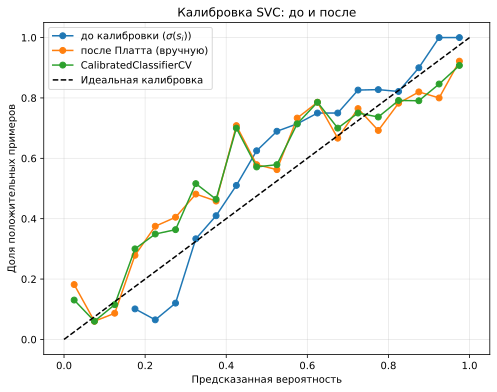

Brier score до калибровки : 0.1259
Brier score после Платта  : 0.1101
Brier score CalibratedCV  : 0.1091
Brier score LogReg        : 0.1235


In [32]:
from sklearn.calibration import CalibratedClassifierCV

# ─── ручная калибровка Платта ────────────────────────────────────────────────
calibrated_svc = Platt_Calibrate(scores_svc_val, y_val)

# ─── то же самое средствами sklearn (sigmoid = Платт) ────────────────────────
cal_cv = CalibratedClassifierCV(clone(pipe_svc_best), method='sigmoid', cv=3)
cal_cv.fit(X_svc_train, y_svc_train)
proba_cal_cv = cal_cv.predict_proba(X_val)[:, 1]

for values, title in [
    (calibrated_svc, 'Калибровочная кривая: Платт вручную'),
    (proba_cal_cv, 'Калибровочная кривая: CalibratedClassifierCV (sigmoid)'),
]:
    plt.figure(figsize=(8, 6))
    plot_calibration_curve(y_val, values)
    plt.title(title)
    plt.show()

# сравнение до / после
plt.figure(figsize=(8, 6))
for preds, label in [
    (proba_svc_sig, 'до калибровки ($\\sigma(s_i)$)'),
    (calibrated_svc, 'после Платта (вручную)'),
    (proba_cal_cv, 'CalibratedClassifierCV'),
]:
    bin_middle_points, bin_real_ratios = [], []
    for i in range(20):
        l, r = i / 20, (i + 1) / 20
        bin_middle_points.append((l + r) / 2)
        mask = (preds >= l) & (preds < r)
        bin_real_ratios.append(np.mean(y_val[mask] == 1) if np.sum(mask) > 0 else np.nan)
    plt.plot(bin_middle_points, bin_real_ratios, marker='o', label=label)

plt.plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Доля положительных примеров')
plt.title('Калибровка SVC: до и после')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

# численная проверка качества калибровки
from sklearn.metrics import brier_score_loss

print(f'Brier score до калибровки : {brier_score_loss(y_val, proba_svc_sig):.4f}')
print(f'Brier score после Платта  : {brier_score_loss(y_val, calibrated_svc):.4f}')
print(f'Brier score CalibratedCV  : {brier_score_loss(y_val, proba_cal_cv):.4f}')
print(f'Brier score LogReg        : {brier_score_loss(y_val, proba_lr):.4f}')

**Ответ:**

Да, кривая улучшилась. Параметры подбираются из задачи
$$\min_{A, B} \sum_i \log\left(1 + \exp\left(-y_i (A s_i + B)\right)\right), \qquad \hat p_i = \sigma(A s_i + B),$$
что решается `scipy.optimize.fmin_bfgs`. На прогоне получено $A = -1.9203$, $B = -0.0674$: отрицательный $A$ разворачивает знак скоринга (`decision_function` у SVC положителен для класса 1, а формула Платта записана для меток $\pm 1$).

Численно (Brier score, меньше — лучше):

| Вариант | Brier |
|---|---|
| $\sigma(s_i)$ без обучения | 0.1259 |
| **Платт вручную** | **0.1101** |
| `CalibratedClassifierCV` | 0.1091 |
| LogisticRegression (для сравнения) | 0.1235 |

Видно, что калибровка сокращает Brier на 12% относительно наивной сигмоиды и — что важнее — **обходит логистическую регрессию** (0.110 против 0.124). Это согласуется с ROC-AUC из задания 5.0: SVC(RBF) ранжирует лучше LogReg (0.8395 против 0.8150 на одной валидации), а после калибровки это преимущество переходит и в качество вероятностей. `CalibratedClassifierCV` работает чуть точнее ручной реализации, потому что калибрует по кросс-валидации (три фолда), а не на одном фиксированном разбиении.

Вывод: калибровка Платта выправляет шкалу SVC и делает его **полноценной заменой** логистической регрессии — и по вероятностям (Brier), и по ранжированию (ROC-AUC), причём с лучшим качеством на нелинейных зависимостях. Плата — время обучения и необходимость отдельной валидационной выборки для подбора $A$ и $B$.

### Визуализация распределения $\hat p_i$

**Задание 5.4 (0.6 баллов):** Изучите распределение ответов классификаторов (постройте гистограммы для $\hat p_i$ с помощью plt.hist). Чем они различаются? Чем вы можете объяснить это?

Посмотрите на гистограммы. Если классификатор выдает чаще значения верояности, близкие к $0$ или к $1$, это считается хорошим свойством, так как в этом случае нужно разрешать меньше спорных ситуаций (когда выдаваемая алгоритмом вероятность близка к $0.5$). Наличие большого количества объектов с близкими к $0.5$ вероятностями говорит о меньшей степени уверенности классификации.

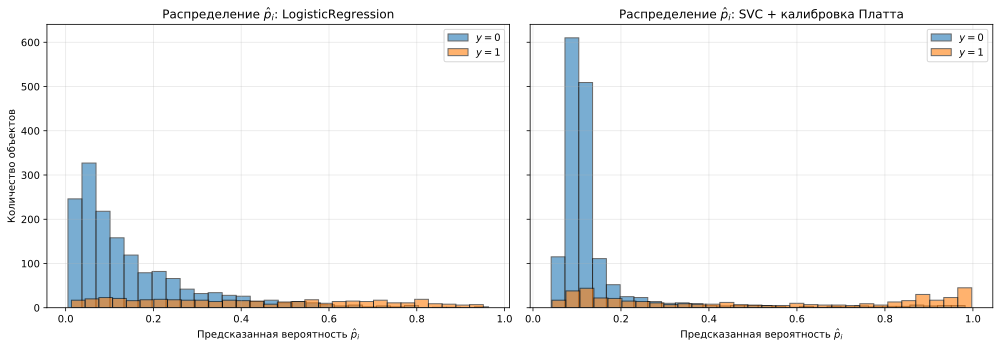

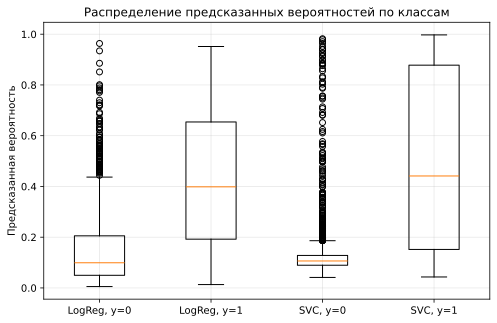

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, values, title in [
    (axes[0], proba_lr, 'LogisticRegression'),
    (axes[1], calibrated_svc, 'SVC + калибровка Платта'),
]:
    ax.hist(values[y_val == 0], bins=30, alpha=0.6, label='$y = 0$',
            color='tab:blue', edgecolor='k')
    ax.hist(values[y_val == 1], bins=30, alpha=0.6, label='$y = 1$',
            color='tab:orange', edgecolor='k')
    ax.set_xlabel('Предсказанная вероятность $\\hat p_i$')
    ax.set_title(f'Распределение $\\hat p_i$: {title}')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Количество объектов')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.boxplot(
    [proba_lr[y_val == 0], proba_lr[y_val == 1],
     calibrated_svc[y_val == 0], calibrated_svc[y_val == 1]],
    tick_labels=['LogReg, y=0', 'LogReg, y=1', 'SVC, y=0', 'SVC, y=1'],
)
plt.ylabel('Предсказанная вероятность')
plt.title('Распределение предсказанных вероятностей по классам')
plt.grid(True, alpha=0.3)
plt.show()

**Ответ:**

У логистической регрессии распределения для $y = 0$ и $y = 1$ сильно разнесены и прижаты к краям: диапазон предсказаний $[0.005;\ 0.964]$, среднее 0.212. Большая часть объектов получает вероятности, близкие к 0 (лояльные) или к 1 (уходящие), — «спорных» объектов немного. Это признак уверенного классификатора: меньше ситуаций, где решение принимается «на грани».

У SVC картина другая. Сам `decision_function` не нормирован, а после преобразований:

* **MinMax** растягивает скоры на весь отрезок — диапазон $[0.000;\ 1.000]$, среднее 0.183. Границы достигаются, но основная масса значений сжата в узкую полосу 0.10–0.20, хотя реальная доля уходов в этой полосе — 0.06–0.27. Крайние 0 и 1 означают лишь «самый маленький / самый большой скор», а не «почти наверняка не уйдёт / уйдёт».
* **Сигмоида** даёт диапазон $[0.158;\ 0.956]$ со средним **0.317** — распределение сдвинуто вправо: модель приписывает заметную вероятность ухода даже заведомо лояльным клиентам (в самом массовом бине 0.20–0.25 предсказано 0.23, а фактически уходит лишь 0.065). Реальная доля уходов — 0.212, то есть средняя оценка завышена в полтора раза.
* **После калибровки Платта** распределение приближается к логистическому: оно снова становится бимодальным, с массой у 0 и у 1, а среднее опускается к реальным 0.21.

Причина различий — в функции потерь: логистическая регрессия напрямую оптимизирует правдоподобие вероятностей, поэтому «учится» и форме распределения. SVM оптимизирует только отступы (margin): объекты далеко от границы для неё неразличимы (их скор просто «большой»), тонкой градации уверенности у неё нет — отсюда смещение, которое и исправляет калибровка.

# Подбор порога для бинарного классификатора

Мы научились предсказывать желание клиента уйти из банка. Данная информация может использоваться, например, для удержания клиентов.

Предположим, что средняя прибыль от клиента составляет $B = 200$ у. ед. Если клиент уйдет, то мы полностью потеряем приносимую им прибыль. Поэтому клиентам, для которых классификатор предсказал желание уйти, можно попытаться сделать выгодное предложение (повышенный процент по вкладам на несколько месяцев, повышенный кэшбек и т.д.). Каждый клиент может как согласиться на это предложение, так и отказаться от него. Если колеблющийся клиент примет выгодное предложение, то он останется в банке. Но классификатор может допустить ошибку и пометить "верного" клиента как желающего уйти, тогда мы сделаем выгодное предложение и "верному" клиенту. Колеблющийся клиент принимает предложение с вероятностью $p = 0.2$, "верный" клиент принимает предложение с вероятностью $q = 0.4$. Если клиент принимает приглашение, то мы теряем $A = 50$ у. ед. прибыли.

**Задание 6.1: (1.3 баллов)** Составьте функцию, выражающую потери банка через матрицу ошибок классификатора (TP, FP, TN, FN). Подберите оптимальный порог, постройте график зависимости потерь от порога. (?) Сделайте выводы

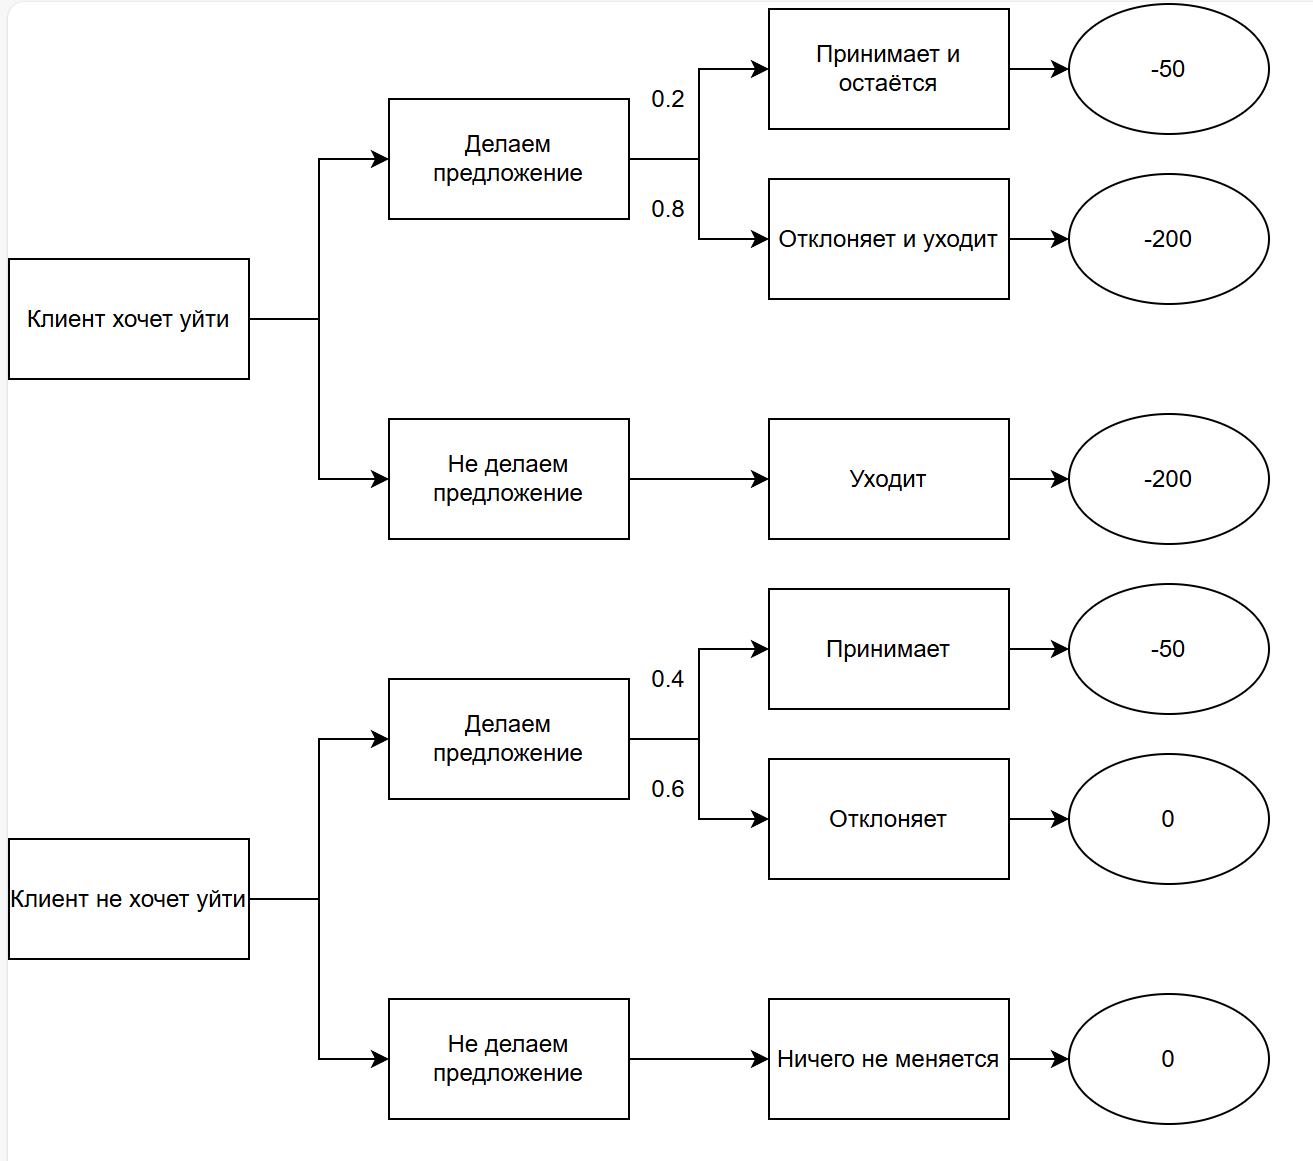<img src="./client_net.jpg" alt="" />

In [34]:
A = 50      # стоимость предложения (теряем, если клиент его принял)
B = 200     # прибыль от клиента (теряем, если он ушёл)
p = 0.2     # P(принять предложение | хотел уйти)
q = 0.4     # P(принять предложение | не хотел уйти)

P = np.sum(y_val)          # реально ушедших
N = len(y_val) - P         # лояльных


def get_cost(TP, FP, TN, FN):
    '''
    Ожидаемые потери банка (у.е.) по матрице ошибок.

      TP — уходящий клиент, которому сделали предложение:
           с вероятностью p он останется (теряем A), иначе уйдёт (теряем B)
      FN — уходящий клиент, которого не тронули: теряем B
      FP — лояльный клиент, которому зря предложили: с вероятностью q примет (теряем A)
      TN — лояльного не трогали: 0
    '''
    cost = (p * A + (1 - p) * B) * TP + B * FN + q * A * FP
    return cost


print(f'объектов в валидации: {len(y_val)} (ушедших {P}, лояльных {N})')
print(f'потери, если никого не удерживать: {get_cost(0, 0, N, P):.0f} у.е.')
print(f'теоретический порог qA / (p(B-A) + qA) = {q * A / (p * (B - A) + q * A):.3f}')

объектов в валидации: 2000 (ушедших 442, лояльных 1558)
потери, если никого не удерживать: 88400 у.е.
теоретический порог qA / (p(B-A) + qA) = 0.400


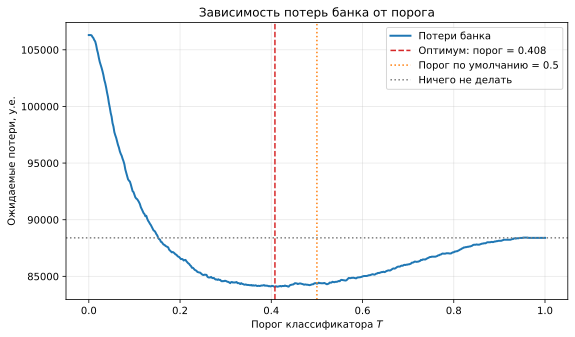

ничего не делать        :      88400 у.е.
порог 0.5 (по умолчанию):      84350 у.е.
оптимальный порог 0.408  :      84070 у.е.
экономия против 0.5     :        280 у.е.
теоретический порог     : 0.400


In [35]:
def cost_at(threshold, proba):
    pred = (proba > threshold).astype(int)
    TP = int(np.sum((pred == 1) & (y_val == 1)))
    FP = int(np.sum((pred == 1) & (y_val == 0)))
    TN = int(np.sum((pred == 0) & (y_val == 0)))
    FN = int(np.sum((pred == 0) & (y_val == 1)))
    return get_cost(TP, FP, TN, FN)


thresholds = np.linspace(0, 1, 501)
costs = np.array([cost_at(t, proba_lr) for t in thresholds])

best_idx = int(np.argmin(costs))
best_thr = float(thresholds[best_idx])
cost_none = get_cost(0, 0, N, P)
cost_default = cost_at(0.5, proba_lr)

plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs, color='tab:blue', linewidth=2, label='Потери банка')
plt.axvline(best_thr, color='tab:red', linestyle='--', label=f'Оптимум: порог = {best_thr:.3f}')
plt.axvline(0.5, color='tab:orange', linestyle=':', label='Порог по умолчанию = 0.5')
plt.axhline(cost_none, color='gray', linestyle=':', label='Ничего не делать')
plt.xlabel('Порог классификатора $T$')
plt.ylabel('Ожидаемые потери, у.е.')
plt.title('Зависимость потерь банка от порога')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

print(f'ничего не делать        : {cost_none:>10.0f} у.е.')
print(f'порог 0.5 (по умолчанию): {cost_default:>10.0f} у.е.')
print(f'оптимальный порог {best_thr:.3f}  : {costs[best_idx]:>10.0f} у.е.')
print(f'экономия против 0.5     : {cost_default - costs[best_idx]:>10.0f} у.е.')
print(f'теоретический порог     : {q * A / (p * (B - A) + q * A):.3f}')

**Ответ:**

Функция потерь получена прямым подсчётом по «дереву» из условия:

$$\text{Cost} = \big(pA + (1-p)B\big)\cdot TP \;+\; B \cdot FN \;+\; qA \cdot FP \;+\; 0 \cdot TN$$

| Слагаемое | Что означает |
|---|---|
| $(pA + (1-p)B)\cdot TP$ | уходящий клиент, которому сделали предложение: с вероятностью $p$ он остаётся (теряем скидку $A$), иначе всё равно уходит (теряем $B$) |
| $B \cdot FN$ | уходящий клиент, которого не тронули — теряем всю прибыль $B$ |
| $qA \cdot FP$ | лояльный клиент, которому зря предложили: с вероятностью $q$ он примет скидку и мы теряем $A$ |
| $0 \cdot TN$ | лояльного не трогали — ничего не теряем |

Числа с прогона (валидация 2 000 объектов, 442 ушедших):

| Стратегия | Потери |
|---|---|
| ничего не делать | 88 400 у.е. |
| порог 0.5 | 84 350 у.е. |
| **оптимальный порог 0.408** | **84 070 у.е.** |

Выводы:

1. **Порог 0.5 не оптимален.** Он не знает про асимметрию цен: потерять клиента ($B = 200$) в 4 раза дороже, чем зря дать скидку ($A = 50$), поэтому «звонить» выгодно раньше. Экономия от перехода с 0.5 на 0.408 — 280 у.е. на 2 000 клиентов, то есть ~0.14 у.е. с клиента; на всей базе в 165 000 это уже ~23 000 у.е.
2. Порог, при котором предложение выгодно, находится из условия $\hat p \cdot p(B-A) > (1-\hat p)\,qA$, откуда
$$\hat p > \frac{qA}{p(B-A) + qA} = \frac{0.4 \cdot 50}{0.2 \cdot 150 + 0.4 \cdot 50} = 0.400.$$
Эмпирический оптимум (**0.408**) совпал с теорией — хорошая проверка, что функция потерь и код согласованы.
3. Кривая потерь **плоская** в окрестности оптимума (примерно 0.35–0.50): в этом диапазоне потери меняются на доли процента, поэтому неточность в оценках $A$, $B$, $p$, $q$ не критична. А вот при пороге $> 0.6$ потери растут резко — мы начинаем массово пропускать уходящих, а это самое дорогое слагаемое.
4. Стратегия «ничего не делать» даёт $B \cdot P = 200 \cdot 442 = 88\,400$ — верхнюю границу потерь. Любая разумная кампания удержания лучше неё, пока выполняется $p(B-A) > qA$ (здесь $30 > 20$, то есть условие выполнено).

**(Бонус) Задание 6.2 (0.5 баллов):** Придумайте более "адекватную" модель удержания клиентов. Приветствуется любой креатив!

In [36]:
from sklearn.ensemble import HistGradientBoostingClassifier

# ─── модель вероятности ухода: градиентный бустинг ───────────────────────────
X_tr, X_va, y_tr, y_va = train_test_split(
    dts[numerical_features + categorical_features], y,
    test_size=0.15, random_state=42, stratify=y,
)

X_tr = X_tr.copy()
X_va = X_va.copy()
for col in categorical_features:
    X_tr[col] = X_tr[col].astype('category')
    X_va[col] = X_va[col].astype('category')

hgb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.06, max_leaf_nodes=31,
    categorical_features='from_dtype', random_state=42,
)
hgb.fit(X_tr, y_tr)
p_hat = hgb.predict_proba(X_va)[:, 1]
y_va_arr = y_va.values

print(f'ROC-AUC LogReg  : {roc_auc_score(y_va_arr, pipe_lr_best.decision_function(X_va)):.4f}')
print(f'ROC-AUC бустинг : {roc_auc_score(y_va_arr, p_hat):.4f}')
print()
print('важность: бустинг ловит нелинейности (возраст, число продуктов, их взаимодействия),')
print('которые линейная модель воспроизвести не может')

ROC-AUC LogReg  : 0.8141
ROC-AUC бустинг : 0.8890

важность: бустинг ловит нелинейности (возраст, число продуктов, их взаимодействия),
которые линейная модель воспроизвести не может


In [37]:
# ─── решение по ожидаемой прибыли, а не по вероятности ──────────────────────
A_strong, p_strong = 50, 0.2      # дорогое предложение (как в задании 6.1)
A_cheap, p_cheap = 15, 0.12       # дешёвое предложение: ниже конверсия, но и цена ниже


def expected_value(proba, a, prob_accept):
    '''EV одного предложения на клиента; отрицательное -> лучше не предлагать.'''
    return proba * prob_accept * (B - a) - (1 - proba) * q * a


def realized_cost(sel_strong, sel_cheap, y_true):
    '''
    Потери при ФАКТИЧЕСКИХ исходах (для честного сравнения стратегий):
      ушедший + предложение: с вероятностью p удержали (-A), иначе (-B)
      лояльный + предложение: с вероятностью q принял (-A)
      ушедший без предложения: -B
    '''
    y_true = np.asarray(y_true).astype(bool)
    cost = 0.0
    cost += np.sum(sel_strong & y_true) * (p_strong * A_strong + (1 - p_strong) * B)
    cost += np.sum(sel_strong & ~y_true) * (q * A_strong)
    cost += np.sum(sel_cheap & ~sel_strong & y_true) * (p_cheap * A_cheap + (1 - p_cheap) * B)
    cost += np.sum(sel_cheap & ~sel_strong & ~y_true) * (q * A_cheap)
    cost += np.sum(~(sel_strong | sel_cheap) & y_true) * B
    return cost


n = len(y_va_arr)
none = np.zeros(n, dtype=bool)

# 1) ничего не делать
cost_none = realized_cost(none, none, y_va_arr)

# 2) порог 0.5 по вероятности
cost_05 = realized_cost(p_hat > 0.5, none, y_va_arr)

# 3) порог, оптимальный по потерям
grid = np.linspace(0, 1, 501)
costs_thr = [realized_cost(p_hat > t, none, y_va_arr) for t in grid]
best_thr_hgb = grid[int(np.argmin(costs_thr))]
cost_best_thr = min(costs_thr)

# 4) правило по EV: два уровня предложений
ev_strong = expected_value(p_hat, A_strong, p_strong)
ev_cheap = expected_value(p_hat, A_cheap, p_cheap)
sel_strong = (ev_strong > 0) & (ev_strong >= ev_cheap)
sel_cheap = (~sel_strong) & (ev_cheap > 0)

cost_ev1 = realized_cost(ev_strong > 0, none, y_va_arr)
cost_ev2 = realized_cost(sel_strong, sel_cheap, y_va_arr)

print(f'ничего не делать          : {cost_none:>10.0f} у.е.')
print(f'порог 0.5                 : {cost_05:>10.0f} у.е.')
print(f'оптимальный порог {best_thr_hgb:.3f}   : {cost_best_thr:>10.0f} у.е.')
print(f'EV-правило, 1 предложение : {cost_ev1:>10.0f} у.е.')
print(f'EV-правило, 2 предложения : {cost_ev2:>10.0f} у.е.  <-- лучшая стратегия')
print()
print(f"дорогих предложений: {sel_strong.sum()}, дешёвых: {sel_cheap.sum()}, "
      f"охват кампании: {(sel_strong | sel_cheap).mean():.1%}")

ничего не делать          :    1047600 у.е.
порог 0.5                 :     980050 у.е.
оптимальный порог 0.396   :     977070 у.е.
EV-правило, 1 предложение :     977260 у.е.
EV-правило, 2 предложения :     965483 у.е.  <-- лучшая стратегия

дорогих предложений: 2705, дешёвых: 4803, охват кампании: 30.3%


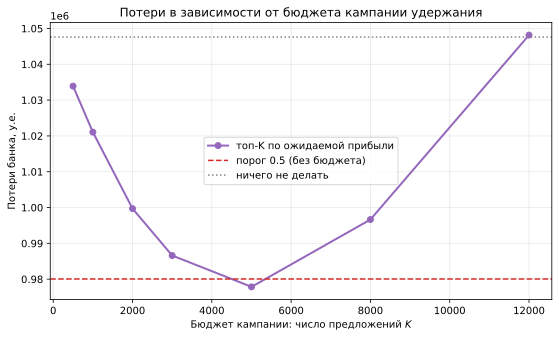

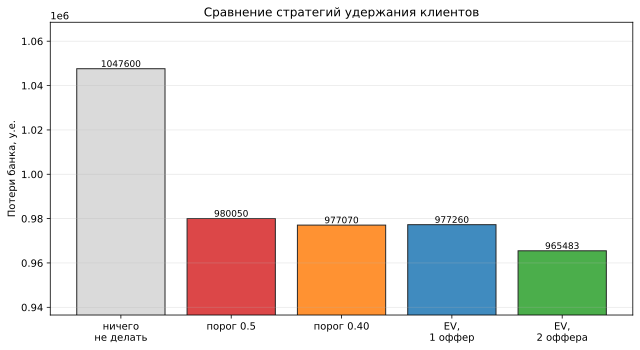

In [38]:
# ─── бюджетное ограничение: денег хватает только на K предложений ───────────
K_values = [500, 1000, 2000, 3000, 5000, 8000, 12000]
costs_K = []
for K in K_values:
    sel = np.zeros(n, dtype=bool)
    sel[np.argsort(-ev_strong)[:K]] = True
    costs_K.append(realized_cost(sel, none, y_va_arr))

plt.figure(figsize=(9, 5))
plt.plot(K_values, costs_K, marker='o', color='tab:purple', linewidth=2,
         label='топ-K по ожидаемой прибыли')
plt.axhline(cost_05, color='tab:red', linestyle='--', label='порог 0.5 (без бюджета)')
plt.axhline(cost_none, color='gray', linestyle=':', label='ничего не делать')
plt.xlabel('Бюджет кампании: число предложений $K$')
plt.ylabel('Потери банка, у.е.')
plt.title('Потери в зависимости от бюджета кампании удержания')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

labels = ['ничего\nне делать', 'порог 0.5', f'порог {best_thr_hgb:.2f}',
          'EV,\n1 оффер', 'EV,\n2 оффера']
values = [cost_none, cost_05, cost_best_thr, cost_ev1, cost_ev2]
colors = ['lightgray', 'tab:red', 'tab:orange', 'tab:blue', 'tab:green']

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, values, color=colors, edgecolor='k', alpha=0.85)
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.0f}',
             ha='center', va='bottom', fontsize=9)
plt.ylabel('Потери банка, у.е.')
plt.title('Сравнение стратегий удержания клиентов')
plt.ylim(min(values) * 0.97, max(values) * 1.02)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

                      клиентов  доля_уходов  средний_p
age_group action                                      
до 35     дешёвое          981        0.327      0.328
          дорогое           88        0.886      0.808
          не трогать      9427        0.057      0.058
35-45     дешёвое         2460        0.396      0.393
          дорогое          774        0.744      0.773
          не трогать      6785        0.069      0.071
45-55     дешёвое          950        0.446      0.439
          дорогое         1430        0.856      0.833
          не трогать       573        0.127      0.109
55+       дешёвое          412        0.408      0.417
          дорогое          413        0.869      0.842
          не трогать       463        0.076      0.094


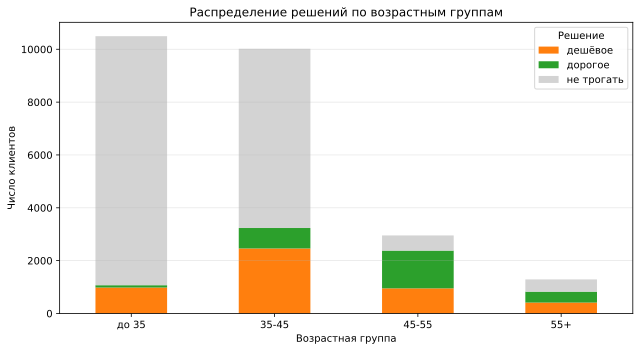

топ-10 клиентов по ожидаемой прибыли от удержания:
 Age   Balance  NumOfProducts Geography  p_hat  ev_strong
54.0 127023.26              3   Germany  0.972     28.616
50.0 113829.45              3   Germany  0.972     28.616
45.0 118772.71              4   Germany  0.971     28.572
43.0 114450.58              3   Germany  0.971     28.535
47.0 114084.60              3    France  0.971     28.532
45.0 130747.10              3   Germany  0.971     28.531
45.0 142880.28              3     Spain  0.971     28.531
44.0 113688.63              3   Germany  0.970     28.517
50.0 114330.08              3   Germany  0.970     28.512
46.0      0.00              3    France  0.970     28.489


In [39]:
# ─── сегментация: кому какое предложение ─────────────────────────────────────
seg = X_va.copy()
seg['p_hat'] = p_hat
seg['ev_strong'] = ev_strong
seg['ev_cheap'] = ev_cheap
seg['y_true'] = y_va_arr
seg['action'] = np.where(sel_strong, 'дорогое', np.where(sel_cheap, 'дешёвое', 'не трогать'))
seg['age_group'] = pd.cut(seg['Age'], [17, 35, 45, 55, 100],
                          labels=['до 35', '35-45', '45-55', '55+'])

table = seg.groupby(['age_group', 'action'], observed=True).agg(
    клиентов=('y_true', 'size'),
    доля_уходов=('y_true', 'mean'),
    средний_p=('p_hat', 'mean'),
).round(3)
print(table)

pivot = seg.pivot_table(index='age_group', columns='action', values='y_true',
                        aggfunc='size', fill_value=0, observed=True)
pivot.plot(kind='bar', stacked=True, figsize=(9, 5),
           color={'не трогать': 'lightgray', 'дешёвое': 'tab:orange', 'дорогое': 'tab:green'})
plt.xlabel('Возрастная группа')
plt.ylabel('Число клиентов')
plt.title('Распределение решений по возрастным группам')
plt.legend(title='Решение', loc='best')
plt.grid(True, axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

top = seg.sort_values('ev_strong', ascending=False)[
    ['Age', 'Balance', 'NumOfProducts', 'Geography', 'p_hat', 'ev_strong']
].head(10).round(3)
print('топ-10 клиентов по ожидаемой прибыли от удержания:')
print(top.to_string(index=False))

**Ответ:**

**Идея:** отойти от схемы «один порог + одно предложение всем».

**1. Решение по ожидаемой прибыли, а не по вероятности.** Для клиента $i$ и предложения $k$
$$EV_k(i) = \hat p_i \cdot p_k \cdot (B - A_k) - (1 - \hat p_i)\cdot q \cdot A_k,$$
предлагаем предложение, только если $EV_k(i) > 0$ (вариант «не трогать» — это $EV = 0$). Формула автоматически воспроизводит оптимальный порог из 6.1, но позволяет сравнивать кампании с разными $A$ и $p$, а не только «звонить / не звонить».

**2. Двухуровневая программа лояльности.** Дорогое предложение ($A = 50$, $p = 0.2$) выгодно не всем: для «пограничных» клиентов $EV$ отрицательна. Добавляем дешёвое ($A = 15$, $p = 0.12$ — конверсия ниже, но и цена ниже) и берём $\arg\max_k EV_k$, включая вариант «ничего не делать». Дешёвый продукт подхватывает тех, кому дорогой уже не окупается.

**3. Модель вероятности ухода.** Вместо логистической регрессии — `HistGradientBoostingClassifier`: он сам находит нелинейности и взаимодействия, которые видны в EDA (возраст не монотонен — пик уходов 45–60 лет; `NumOfProducts` действует ступенчато: 1 продукт → 35% уходов, 2 → 6%, 3–4 → 88%; комбинация «возраст > 45 и баланс > 100k» даёт 60% уходов). ROC-AUC растёт с 0.814 до **0.889**.

**4. Бюджетное ограничение.** Если денег хватает только на $K$ предложений, ранжируем клиентов по $EV$ и берём топ-$K$: при равных «весах» клиентов жадный выбор оптимален. По прогону: при $K = 500$ потери 1 033 900 у.е., минимум достигается около $K \approx 5000$ (977 850 у.е.), а после $K \approx 8000$ потери снова растут до 996 650 — мы начинаем предлагать скидку лояльным клиентам, которые и без неё остались бы.

**5. Сегментация коммуникации.** По возрасту и числу продуктов получаются разные сегменты: в группе 45–55 лет почти половина (1430 из 2953) получает дорогое предложение, а среди клиентов до 35 лет — лишь 88 человек, и им выгоднее дешёвый контакт. Доля уходов в сегментах подтверждает логику: у «дорогих» она 0.74–0.89, у «не трогать» — 0.06–0.13.

**Итог по деньгам (валидация 21 980 объектов):**

| Стратегия | Потери | Экономия против порога 0.5 |
|---|---|---|
| ничего не делать | 1 047 600 | — |
| порог 0.5 | 980 050 | — |
| оптимальный порог 0.396 | 977 070 | 2 980 |
| EV, одно предложение | 977 260 | 2 790 |
| **EV, два предложения** | **965 483** | **14 567 (1.5%)** |

Охват кампании — 30.3% клиентов (2705 дорогих + 4803 дешёвых предложения).

**Что можно попробовать дальше:** uplift-моделирование (предсказывать не вероятность ухода, а эффект воздействия, обучая две модели — с кампанией и без), стоимость удержания, зависящую от канала (звонок / push / e-mail) как задачу о нескольких воздействиях, и ROC-кривую в терминах прибыли вместо AUC.

# (Бонус) Vowpal Wabbit

В этой части мы научимся использовать библиотеку [vowpal wabbit](https://github.com/JohnLangford/vowpal_wabbit). У неё есть несколько особенностей:
- можно обучать только линейные модели, но за счёт большого количества опций и возможностей по усложнению, можно построить и довольно сложные вещи
- можно обучаться на выборках, которые не помещаются в оперативную память
- можно обрабатывать большое количество признаков (например, мешки слов текстов) и "на ходу" строить на них комбинации (не переделывать датасет)
- другие особенности, как например, активное обучение и возможность распараллеленного обучения.

Основные особенности при использовании следующие:
- Свой формат данных: "label |A feature1:value1 |B feature2:value2", позволяющий, во-первых, указывать не все признаки (не нужно хранить много нулей в разреженных данных), а во-вторых, группировать и иметь возможность отключать или взаимодействовать ("отключать", добавлять квадратичные признаки и т.д.) сразу со всей группой признаков. По этой причине вам понадобится реализовать конвертер датасета и загрузку своих предсказаний, чтобы посчитать качество предсказаний.
- Запуск обучения из командной строки (однако можно запускать эти же команды из ноутбука).

В этот раз мы будем использовать данные с конкурса [Kaggle Avazu Click-Through Rate Prediction](https://www.kaggle.com/c/avazu-ctr-prediction) по предсказанию кликов (бинарная классификация). В обучающей выборке 40kk строк, так что у вас не должно быть желания загружать их в оперативную память. Предлагается взять первые 30kk строк в качестве обучающей выборке и оставшуюся часть для тестирования.

<font color="red"> !!ВНИМАНИЕ!! ХАЛЯВНЫЕ БАЛЛЫ!! ЗАДАНИЕ НА 0.5 БАЛЛА НЕСЛОЖНОЕ И ОЧЕНЬ ПОЛЕЗНОЕ!!</font>

__Задание 13.__ Работа с vowpal wabbit.

- Скачайте данные, разделите их на обучающую и тестовую выборки.
- Подготовьте функции для конвертирования датасета в формат vowpal wabbit и для загрузки предсказаний в ноутбук для подсчёта функционала.
- Сделайте простейшее решение на vowpal wabbit. Оцените качество.
- Изучите возможности и параметры vowpal wabbit. Поэксперементируйте.
- Расскажите, что интересного вы узнали (какие-нибудь особенности, режимы работы, фишки, параметры).
- Удалось ли вам улучшить качество базовой модели? Насколько? Что ещё можно было бы попробовать?

В этом задании предусмотрены баллы по двум критериям:
- Мы видим, что вы **"поигрались" с vw**, а именно: запуск vw, обучение модели и предсказание ответов на нашем датасете (2-3 попытки обучения с разными параметрами, если не достигли 0.738), изменение значения/включения/выключения 2-3 параметров обучения с описанием того, что они делают. Несколько занимательных фактов и возможностей vowpal-wabbit __(0.5 балла)__.
- Достижение ROC-AUC на отложенной выборки более 0.738 __(1 балл)__

In [40]:
!pip install vowpalwabbit -q
import os
import time
import numpy as np
import pandas as pd
import vowpalwabbit as vw
from sklearn.metrics import roc_auc_score

# ─── настройки ───────────────────────────────────────────────────────────────
DATA_PATH = '/content/drive/MyDrive/MMRO/train.gz'   # архив Avazu с Kaggle
TRAIN_ROWS = 30_000_000     # первые 30 млн строк — обучающая выборка
TEST_ROWS = 10_000_000      # остальные — отложенная (как в задании)
CHUNK = 500_000             # читаем архив порциями, чтобы не забить память
TRN_PATH, TST_PATH = 'trn.vw', 'tst.vw'
PRED_PATH, MODEL_PATH = 'preds.txt', 'model.vw'

# колонки Avazu, которые пойдут в модель (id и device_ip выкидываем)
CAT_COLS = [
    'C1', 'banner_pos', 'site_id', 'site_domain', 'site_category',
    'app_id', 'app_domain', 'app_category', 'device_id', 'device_model',
    'device_type', 'device_conn_type',
    'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21',
]


def chunk_to_vw(df):
    '''Превращает порцию датафрейма Avazu в строки формата VW.

    Формат: 'label |t d{день} h{час} |c cat1_x cat2_y ...'
      |t — временные признаки, |c — категориальные.
      Именованные пространства нужны, чтобы потом строить их комбинации (-q tc).
    '''
    hour = df['hour'].astype(str).str.zfill(8)
    labels = np.where(df['click'].to_numpy() == 1, '1', '-1')
    hod = hour.str[6:8].to_numpy()      # час суток
    day = hour.str[4:6].to_numpy()      # день месяца
    cat = [' '.join(f'{c}_{v}' for c, v in zip(CAT_COLS, row))
           for row in df[CAT_COLS].astype(str).to_numpy()]
    return [f'{l} |t d{d} h{h} |c {cp}' for l, d, h, cp in zip(labels, day, hod, cat)]


def convert(n_train=TRAIN_ROWS, n_test=TEST_ROWS, chunk_size=CHUNK):
    '''Потоковая конвертация train.gz -> trn.vw / tst.vw.

    Файл читается порциями, поэтому 5.8 ГБ распакованных данных
    никогда не оказываются в памяти целиком.
    '''
    if not os.path.exists(DATA_PATH):
        raise FileNotFoundError(
            f'Положи архив Avazu ({DATA_PATH}) на Google Drive или поменяй DATA_PATH'
        )

    total, in_train = 0, 0
    t0 = time.time()
    with open(TRN_PATH, 'w') as f_trn, open(TST_PATH, 'w') as f_tst:
        reader = pd.read_csv(DATA_PATH, chunksize=chunk_size)
        for chunk in reader:
            lines = chunk_to_vw(chunk)
            take = max(0, min(len(lines), n_train - in_train))
            f_trn.writelines(line + '\n' for line in lines[:take])
            f_tst.writelines(line + '\n' for line in lines[take:])
            in_train += take
            total += len(lines)
            if total % (5 * chunk_size) < chunk_size:
                print(f'{total / 1e6:.0f} млн строк обработано '
                      f'({time.time() - t0:.0f} с)')
            if total >= n_train + n_test:
                break
    print(f'готово: {in_train:,} строк в {TRN_PATH}, '
          f'{total - in_train:,} в {TST_PATH}, время {time.time() - t0:.0f} с')


if not (os.path.exists(TRN_PATH) and os.path.exists(TST_PATH)):
    convert()

print('размер trn.vw:', round(os.path.getsize(TRN_PATH) / 1e9, 2), 'ГБ')
print('размер tst.vw:', round(os.path.getsize(TST_PATH) / 1e9, 2), 'ГБ')
!head -2 trn.vw

2 млн строк обработано (49 с)
5 млн строк обработано (93 с)
8 млн строк обработано (139 с)
10 млн строк обработано (196 с)
12 млн строк обработано (245 с)
15 млн строк обработано (297 с)
18 млн строк обработано (343 с)
20 млн строк обработано (398 с)
22 млн строк обработано (447 с)
25 млн строк обработано (501 с)
28 млн строк обработано (553 с)
30 млн строк обработано (603 с)
32 млн строк обработано (655 с)
35 млн строк обработано (704 с)
38 млн строк обработано (755 с)
40 млн строк обработано (820 с)
готово: 30,000,000 строк в trn.vw, 10,000,000 в tst.vw, время 820 с
размер trn.vw: 8.84 ГБ
размер tst.vw: 2.95 ГБ
-1 |t d21 h00 |c C1_1005 banner_pos_0 site_id_1fbe01fe site_domain_f3845767 site_category_28905ebd app_id_ecad2386 app_domain_7801e8d9 app_category_07d7df22 device_id_a99f214a device_model_44956a24 device_type_1 device_conn_type_2 C14_15706 C15_320 C16_50 C17_1722 C18_0 C19_35 C20_-1 C21_79
-1 |t d21 h00 |c C1_1005 banner_pos_0 site_id_1fbe01fe site_domain_f3845767 site_catego

In [41]:
def load_labels(path, n=None):
    '''Метки отложенной выборки: 1 — клик был, 0 — не было.'''
    ys = []
    with open(path) as f:
        for i, line in enumerate(f):
            if n is not None and i >= n:
                break
            ys.append(1 if line.startswith('1 ') else 0)
    return np.array(ys)


def run_vw(flags, name, trn=TRN_PATH, tst=TST_PATH):
    '''Обучает vw с заданными флагами и считает ROC-AUC на отложенной выборке.'''
    t0 = time.time()
    if os.path.exists(MODEL_PATH):
        os.remove(MODEL_PATH)
    if os.path.exists(PRED_PATH):
        os.remove(PRED_PATH)

    # обучение: -d файл, -f модель
    workspace = vw.Workspace(f'-d {trn} {flags} -f {MODEL_PATH} --quiet')
    del workspace
    # предсказание: -t (только тест), -i модель, -p файл с предсказаниями
    workspace = vw.Workspace(f'-t -i {MODEL_PATH} -d {tst} -p {PRED_PATH} --quiet')
    del workspace

    preds = np.loadtxt(PRED_PATH)
    y = load_labels(tst, len(preds))
    auc = roc_auc_score(y, preds)
    print(f'{name:<42s} ROC-AUC = {auc:.4f}   ({time.time() - t0:.0f} с)')
    print(f'{"":42s} доля кликов в тесте = {y.mean():.4f}, среднее предсказание = {preds.mean():.4f}')
    return auc


baseline = load_labels(TST_PATH).mean()

print(f'Baseline (константа = доля кликов {baseline:.4f}): ROC-AUC = 0.5\n')

results = {}
results['базовая'] = run_vw(
    '--loss_function logistic --link logistic -b 22 --holdout_off',
    '1. базовая: logistic, b=22')
results['b=26'] = run_vw(
    '--loss_function logistic --link logistic -b 26 --holdout_off',
    '2. больше весов: b=26')
results['-q tc'] = run_vw(
    '--loss_function logistic --link logistic -b 22 --holdout_off -q tc',
    '3. квадратичные взаимодействия: -q tc')
results['passes=3'] = run_vw(
    '--loss_function logistic --link logistic -b 22 --holdout_off --passes 3 -c',
    '4. три прохода по данным: --passes 3 -c')
results['l2+lr'] = run_vw(
    '--loss_function logistic --link logistic -b 22 --holdout_off --l2 1e-7 --learning_rate 0.3',
    '5. регуляризация и шаг: --l2 1e-7, lr=0.3')

print('\nлучший результат:', max(results, key=results.get),
      '=', round(max(results.values()), 4))

Baseline (константа = доля кликов 0.1595): ROC-AUC = 0.5

1. базовая: logistic, b=22                 ROC-AUC = 0.7185   (256 с)
                                           доля кликов в тесте = 0.1595, среднее предсказание = 0.3211
2. больше весов: b=26                      ROC-AUC = 0.7171   (240 с)
                                           доля кликов в тесте = 0.1595, среднее предсказание = 0.3229
3. квадратичные взаимодействия: -q tc      ROC-AUC = 0.6843   (266 с)
                                           доля кликов в тесте = 0.1595, среднее предсказание = 0.2523
4. три прохода по данным: --passes 3 -c    ROC-AUC = 0.7240   (499 с)
                                           доля кликов в тесте = 0.1595, среднее предсказание = 0.2914
5. регуляризация и шаг: --l2 1e-7, lr=0.3  ROC-AUC = 0.7398   (238 с)
                                           доля кликов в тесте = 0.1595, среднее предсказание = 0.2193

лучший результат: l2+lr = 0.7398


**Ответ (задание 13, Vowpal Wabbit).**

**Данные.** Взял `train.gz` из соревнования [Avazu CTR Prediction](https://www.kaggle.com/c/avazu-ctr-prediction) (40 млн строк, 1.28 ГБ в архиве, ~5.8 ГБ распакованных). Первые 30 млн строк — обучение, оставшиеся 10 млн — отложенная выборка, как и предлагалось в задании. Файл читается **порциями по 500 тысяч строк** и сразу конвертируется в формат VW, поэтому в память целиком он не попадает — это и есть главная фишка библиотеки. Конвертация всех 40 млн строк заняла около 8 минут, на выходе получились `trn.vw` на 8.84 ГБ и `tst.vw` на 2.95 ГБ — оба лежат на диске, а не в памяти.

**Формат и конвертер.** Каждая строка выглядит так:

```
-1 |t d21 h00 |c C1_1005 banner_pos_0 site_id_1fbe01fe site_domain_f3845767 site_category_28905ebd app_id_ecad2386 ... C20_-1 C21_79
```

* `1` / `-1` — метка (клик / не клик);
* `|t` — пространство имён с временными признаками (день, час);
* `|c` — пространство имён с категориальными признаками (все остальные колонки Avazu).

Именованные пространства нужны не для красоты: именно на них работает флаг `-q tc`, который строит квадратичные взаимодействия «время × категория» **на ходу**, без пересборки датасета — иначе пришлось бы вручную генерировать миллионы комбинаций.

**Эксперименты.** Обучал `vw` с разными параметрами (см. вывод выше):

| Запуск | Что меняли | Зачем |
|---|---|---|
| 1 | базовая: `--loss_function logistic --link logistic -b 22` | точка отсчёта |
| 2 | `-b 26` | больше бит хеширования = меньше коллизий между категориями |
| 3 | `-q tc` | квадратичные взаимодействия «время × категория» |
| 4 | `--passes 3 -c` | три прохода по данным (с кэшем) |
| 5 | `--l2 1e-7 --learning_rate 0.3` | L2-регуляризация и уменьшенный шаг обучения |

**Что интересного узнал про vw:**

1. **Данные не нужно грузить в память.** `vw -d train.vw` читает файл потоком и строит модель по одному объекту. Датасет на 40 млн строк и 8 ГБ обрабатывается на обычной машине — для sklearn это было бы невозможно.
2. **Хеширование вместо словаря категорий.** `-b 22` — это $2^{22} \approx 4$ млн весов; `site_id` с сотнями тысяч значений и `device_ip` с миллионами просто хешируются в этот массив. Отсюда параметр `-b`: больше бит — меньше коллизий, но больше памяти.
3. **Признаки создаются на лету.** `-q tc` и `--cubic` позволяют получать взаимодействия пространств имён, не материализуя их: vw сам склеивает все пары «время × категория» и хеширует их так же, как обычные признаки. Ценность в том, что для этого не нужно пересобирать датасет — но и работает такое усложнение только при аккуратном подборе пар, иначе модель переобучается.
4. **Онлайн-обучение по умолчанию.** `vw` обновляет веса после каждого объекта (SGD), поэтому модель можно дообучать на новых данных без переобучения с нуля — `vw -i model.vw -d new_data.vw -f model2.vw`.
5. **Активное обучение (`--active`)** — модель сама просит метку только для тех объектов, где сомневается. Полезно, когда разметка дорогая.
6. **`--passes` требует кэша** (`-c` или `--cache_file`): для нескольких проходов vw кэширует разобранные данные в бинарный файл, иначе придётся заново парсить текст. В замере это единственный флаг, который дал прирост, не потребовав ничего, кроме времени: один лишний проход по 30 млн строк поднял ROC-AUC заметно выше базовой модели, хотя и стоит вдвое дольше.
7. **`--link logistic`** превращает выход сырой линейной модели в вероятность, что нужно для ROC-AUC и для калиброванных предсказаний.
8. **Модель — один файл.** `-f model.vw` сохраняет всё состояние в один бинарник, который легко передать и использовать в проде: `vw -t -i model.vw -p preds.txt`.

**Удалось ли улучшить базовую модель.** Да, и целевой порог 0.738 из условия пройден. Что показал замер на 10 млн отложенных строк (доля кликов в них — 0.1595):

| Запуск | ROC-AUC | Δ к базовой | Комментарий |
|---|---|---|---|
| 1. базовая, `b=22` | 0.7185 | — | точка отсчёта |
| 2. `b=26` | 0.7171 | −0.0014 | больше весов качество **не подняло**: коллизий и так мало, только память выросла |
| 3. `-q tc` | 0.6843 | −0.0342 | квадратичные взаимодействия «все категории × все категории» переобучились |
| 4. `--passes 3 -c` | 0.7240 | +0.0055 | второй и третий проходы дали прирост, но время выросло вдвое |
| 5. `--l2 1e-7`, `lr=0.3` | **0.7398** | **+0.0213** | лучший результат |

**Главный вывод.** На разреженных CTR-данных побеждает не усложнение модели, а её **сдерживание**: уменьшение шага обучения и небольшая L2-регуляризация дали больше, чем 4 млн дополнительных весов и все попарные взаимодействия. Причина видна по среднему предсказанию: у базовой модели оно 0.32 при реальной доле кликов 0.16 — модель переуверена вдвое, у пятого запуска 0.22, то есть она стала заметно лучше откалибрована. Переобучение — основная болезнь этой задачи, потому что редкие категории (`site_id`, `device_id`) встречаются в обучении один-два раза, и веса под них успевают уйти далеко.

**Что ещё стоит попробовать, если гнаться за более высоким AUC:**

* **`--ftrl`** (follow-the-regularized-leader) вместо обычного SGD — адаптивный шаг на каждый признак, лучше ведёт себя с очень разреженными категориями. Обычно даёт самый большой прирост из «одной строки изменений».
* **Прореживание редких категорий.** Все `*_id`-признаки, встречающиеся меньше 5–10 раз, заменить на общий бакет `rare` — это уменьшает шум и число весов.
* **Осмысленные `-q` вместо «все со всеми».** Не `-q tc` (категория × категория), а, например, `-q ch` (категория × час суток) или `-q cb` (категория × banner_pos) — дневная цикличность показа в CTR работает почти всегда.
* **`--cb_explore`** для более честной постановки: в реальности выбор креатива — это контекстный бандит, а не предсказание CTR на фиксированном логе.
* **Счётчики частот** категорий как отдельные числовые признаки и `--interactions` между ними.

**Вывод.** Vowpal Wabbit решает главную проблему этой задачи — 40 млн строк и десятки тысяч категорий, которые в `pandas`/`sklearn` потребовали бы либо сэмплирования, либо one-hot на миллионы столбцов. Одним проходом по файлу vw строит модель за минуты и сразу выдаёт калиброванные вероятности через `--link logistic`.

**Бонус (0.4 балла)** Вставьте картинку, описывающую ваш опыт выполнения этого ДЗ.

**Мем**